#Environment

In [ ]:
# SPECIFICATION
# Operating System
!printf "%-22s : %s\n" "Operating System" "$(lsb_release -d | awk -F'\t' '{print $2}')"

# Python Version
!printf "%-22s : %s\n" "Python version" "$(python --version 2>&1 | awk '{print $2}')"

# CPU Model
!printf "%-22s : %s\n" "CPU Model" "$(lscpu | grep 'Model name:' | awk -F': ' '{print $2}' | xargs)"

# Memory
!printf "%-22s : %s\n" "Total Memory" "$(free -h | awk '/Mem:/ {print $2}')"
!free -ght

#GPU
!nvidia-smi

Operating System       : Ubuntu 22.04.3 LTS
Python version         : 3.10.12
CPU Model              : Intel(R) Xeon(R) CPU @ 2.00GHz
Total Memory           : 12Gi
               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.3Gi       4.0Gi        16Mi       6.3Gi        10Gi
Swap:             0B          0B          0B
Total:          12Gi       2.3Gi       4.0Gi
Thu Dec 12 01:20:21 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|============

#Library

In [ ]:
!pip install transformers torch pandas numpy seaborn matplotlib scikit-learn

In [ ]:
!git clone https://github.com/IndoNLP/indonlu

fatal: destination path 'indonlu' already exists and is not an empty directory.


In [ ]:
import os, sys
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import torch
from torch import optim
import torch.nn.functional as F
from tqdm import tqdm

from collections import defaultdict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from transformers import BertForSequenceClassification, BertConfig, BertTokenizer
from nltk.tokenize import TweetTokenizer

from indonlu.utils.forward_fn import forward_sequence_classification
from indonlu.utils.metrics import document_sentiment_metrics_fn
from indonlu.utils.data_utils import DocumentSentimentDataset, DocumentSentimentDataLoader

In [ ]:
###
# common functions
###
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

def count_param(module, trainable=False):
    if trainable:
        return sum(p.numel() for p in module.parameters() if p.requires_grad)
    else:
        return sum(p.numel() for p in module.parameters())

def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def metrics_to_string(metric_dict):
    string_list = []
    for key, value in metric_dict.items():
        string_list.append('{}:{:.2f}'.format(key, value))
    return ' '.join(string_list)

In [ ]:
# Set random seed
set_seed(42)

# Load Model

In [ ]:
# Load Tokenizer and Config
tokenizer = BertTokenizer.from_pretrained('indobenchmark/indobert-base-p1')
config = BertConfig.from_pretrained('indobenchmark/indobert-base-p1')
config.num_labels = DocumentSentimentDataset.NUM_LABELS
print(config.num_labels)
# Instantiate model
model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', config=config)

3


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(50000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

In [ ]:
count_param(model)

124443651

# Prepare Dataset

In [ ]:
from google.colab import files
dataset_train = files.upload()
dataset_val = files.upload()
dataset_test = files.upload()

In [ ]:
train_dataset_path = '/content/final_ikn_train_preprocessed.tsv'
valid_dataset_path = '/content/final_ikn_val_preprocessed.tsv'
test_dataset_path = '/content/final_ikn_test_preprocessed.tsv'

In [ ]:
train_dataset = DocumentSentimentDataset(train_dataset_path, tokenizer, lowercase=True)
valid_dataset = DocumentSentimentDataset(valid_dataset_path, tokenizer, lowercase=True)
test_dataset = DocumentSentimentDataset(test_dataset_path, tokenizer, lowercase=True)

train_loader = DocumentSentimentDataLoader(dataset=train_dataset, max_seq_len=512, batch_size=32, num_workers=16, shuffle=True)
valid_loader = DocumentSentimentDataLoader(dataset=valid_dataset, max_seq_len=512, batch_size=32, num_workers=16, shuffle=False)
test_loader = DocumentSentimentDataLoader(dataset=test_dataset, max_seq_len=512, batch_size=32, num_workers=16, shuffle=False)

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
w2i, i2w = DocumentSentimentDataset.LABEL2INDEX, DocumentSentimentDataset.INDEX2LABEL
print(w2i)
print(i2w)

{'positive': 0, 'neutral': 1, 'negative': 2}
{0: 'positive', 1: 'neutral', 2: 'negative'}


# Fine Tuning & Evaluation

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=3e-6)
model = model.cuda()
history = defaultdict(list)

In [ ]:
# Train
n_epochs = 5
# Training and Validation
for epoch in range(n_epochs):
    # Training loop
    model.train() # Mode pelatihan diaktifkan
    torch.set_grad_enabled(True) # Mengaktifkan perhitungan gradien untuk pelatihan

    # Variabel untuk menyimpan total loss selama pelatihan dan hasil prediksi
    total_train_loss = 0
    list_hyp, list_label = [], [] # Menyimpan prediksi (hypothesis) dan label

    # Progress bar untuk melacak iterasi dalam training loader
    train_pbar = tqdm(train_loader, leave=True, total=len(train_loader))
    for i, batch_data in enumerate(train_pbar):
        # Forward pass, mendapatkan loss, prediksi, dan label dari batch
        loss, batch_hyp, batch_label = forward_sequence_classification(
            model, batch_data[:-1], i2w=i2w, device='cuda'
        )

        # Backward pass, menghitung gradien dan memperbarui parameter model
        optimizer.zero_grad() # Menghapus gradien sebelumnya
        loss.backward() # Backpropagation
        optimizer.step() # Update parameter model menggunakan optimizer

        # Melacak total loss selama pelatihan
        total_train_loss += loss.item()

        # Menggabungkan hasil prediksi dan label aktual untuk menghitung metrik
        list_hyp += batch_hyp
        list_label += batch_label

        # Menampilkan deskripsi progress training
        train_pbar.set_description("(Epoch {}) TRAIN LOSS:{:.4f} LR:{:.8f}".format((epoch+1), total_train_loss/(i+1), get_lr(optimizer)))

    # Menghitung rata-rata training loss untuk satu epoch
    avg_train_loss = total_train_loss / (i+1)
    # Menghitung metrik dan menampilkan hasil pelatihan untuk epoch saat ini
    metrics = document_sentiment_metrics_fn(list_hyp, list_label)
    print("(Epoch {}) TRAIN LOSS:{:.4f} {} LR:{:.8f}".format((epoch+1), total_train_loss/(i+1), metrics_to_string(metrics), get_lr(optimizer)))

    # Menyimpan metrik akurasi dan loss untuk grafik kurva training
    history['train_acc'].append(metrics['ACC'])
    history['train_loss'].append(avg_train_loss)

    # Validation loop
    model.eval() # Mode evaluasi diaktifkan
    torch.set_grad_enabled(False)
    # Mematikan perhitungan gradien selama validasi karena backpropagation tidak dilakukan pada fase ini dan penhematan memori

    # Variabel untuk menyimpan total loss selama validasi dan hasil prediksi
    total_val_loss = 0
    list_hyp, list_label = [], []

    # Progress bar untuk melacak iterasi dalam valid loader
    valid_pbar = tqdm(valid_loader, leave=True, total=len(valid_loader))
    for i, batch_data in enumerate(valid_pbar):
      # Forward pass, mendapatkan loss, prediksi, dan label dari batch
        batch_seq = batch_data[-1]
        loss, batch_hyp, batch_label = forward_sequence_classification(
            model, batch_data[:-1], i2w=i2w, device='cuda'
        )

        # Melacak total loss selama validasi
        total_val_loss += loss.item()

        # Menggabungkan hasil prediksi dan label aktual untuk menghitung metrik
        list_hyp += batch_hyp
        list_label += batch_label

        # Menampilkan deskripsi progress validasi
        valid_pbar.set_description("VALID LOSS:{:.4f} {}".format(total_val_loss/(i+1), metrics_to_string(document_sentiment_metrics_fn(list_hyp, list_label))))

    # Menghitung rata-rata validasi loss untuk satu epoch
    avg_val_loss = total_val_loss / (i+1)

    # Menghitung metrik dan menampilkan hasil validasi untuk epoch saat ini
    metrics = document_sentiment_metrics_fn(list_hyp, list_label)
    print(f"(Epoch {epoch+1}) VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(metrics)}")

    # Menyimpan metrik akurasi dan loss untuk grafik kurva validasi
    history['val_acc'].append(metrics['ACC'])
    history['val_loss'].append(avg_val_loss)

(Epoch 1) TRAIN LOSS:0.7227 LR:0.00000300: 100%|██████████| 235/235 [00:59<00:00,  3.94it/s]


(Epoch 1) TRAIN LOSS:0.7227 ACC:0.71 F1:0.44 REC:0.43 PRE:0.56 LR:0.00000300


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.2094 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:   1%|▏         | 1/79 [00:01<01:20,  1.04s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2306 ACC:0.97 F1:0.49 REC:0.48 PRE:0.50:   4%|▍         | 3/79 [00:01<00:24,  3.16it

(Epoch 1) VALID LOSS:0.6253 ACC:0.77 F1:0.60 REC:0.56 PRE:0.72


  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 2) TRAIN LOSS:0.5928 LR:0.00000300: 100%|██████████| 235/235 [00:52<00:00,  4.47it/s]


...

(Epoch 4) VALID LOSS:0.5944 ACC:0.78 F1:0.64 REC:0.62 PRE:0.68


  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 5) TRAIN LOSS:0.4510 LR:0.00000300: 100%|██████████| 235/235 [00:53<00:00,  4.43it/s]


(Epoch 5) TRAIN LOSS:0.4510 ACC:0.83 F1:0.73 REC:0.70 PRE:0.77 LR:0.00000300


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2792 ACC:0.91 F1:0.32 REC:0.30 PRE:0.33:   1%|▏         | 1/79 [00:01<02:08,  1.64s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 5) VALID LOSS:0.6091 ACC:0.77 F1:0.64 REC:0.62 PRE:0.67


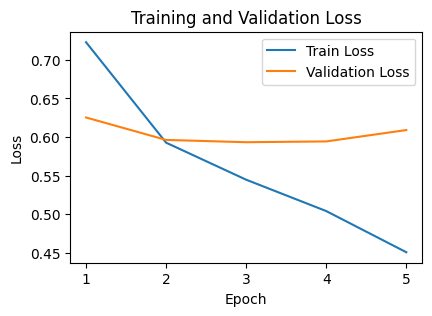

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.plot(range(1, n_epochs + 1), history['train_loss'], label='Train Loss')
plt.plot(range(1, n_epochs + 1), history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.xticks(range(1, n_epochs + 1))
plt.legend()

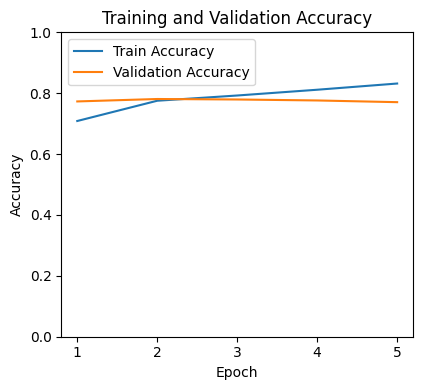

In [ ]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 2)
plt.plot(range(1, n_epochs + 1), history['train_acc'], label='Train Accuracy')
plt.plot(range(1, n_epochs + 1), history['val_acc'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.xticks(range(1, n_epochs + 1))
plt.legend()
plt.ylim([0, 1])

plt.tight_layout()
plt.show()

In [ ]:
# INDOBERT TESTING
# Evaluasi model pada data uji
# Memasukkan model ke mode evaluasi untuk menonaktifkan dropout atau mekanisme pelatihan lainnya
model.eval()

# Menonaktifkan perhitungan gradien selama evaluasi untuk menghemat memori dan mempercepat proses
torch.set_grad_enabled(False)

# Inisialisasi variabel untuk menghitung metrik evaluasi
# total_loss: untuk mencatat total loss
# total_correct: untuk mencatat jumlah prediksi benar
total_loss, total_correct, total_labels = 0, 0, 0
list_hyp, list_label = [], []

# Menampilkan progress evaluasi menggunakan tqdm untuk data loader
pbar = tqdm(test_loader, leave=True, total=len(test_loader))
for i, batch_data in enumerate(pbar):
    # Melakukan prediksi menggunakan model sequence classification
    _, batch_hyp, _ = forward_sequence_classification(model, batch_data[:-1], i2w=i2w, device='cuda')
    list_hyp += batch_hyp

# Membuat DataFrame untuk menyimpan prediksi model
# Kolom 'label' berisi prediksi, dan 'index' berisi indeks data
df = pd.DataFrame({'label': list_hyp}).reset_index()

# Menampilkan DataFrame hasil prediksi
print(df)

# test_metrics = document_sentiment_metrics_fn(list_hyp, list_label)
# print(f"TEST RESULTS: {metrics_to_string(test_metrics)}")

  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 13.02it/s]

      index     label
0         0  negative
1         1   neutral
2         2  negative
3         3  negative
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498   neutral
2499   2499  positive
2500   2500  negative

[2501 rows x 2 columns]


In [ ]:
# PREDICTION RESULT SAVING
# Menyimpan hasil prediksi model ke dalam file

# Memuat dataset uji sebagai DataFrame
# Dataset diharapkan memiliki dua kolom: 'text' dan 'sentiment'
# Separator file disesuaikan dengan format dataset Anda (di sini menggunakan tab '\t')
test_df = pd.read_csv(test_dataset_path, sep='\t', names=['text', 'sentiment'])

# Menambahkan kolom baru 'sentiment_predict' yang berisi hasil prediksi model
test_df['sentiment_predict'] = list_hyp

# Menyimpan dataset uji yang telah diperbarui (dengan prediksi) ke file CSV
# File baru disimpan dengan nama 'test_with_predictions.csv'
output_path = 'test_with_predictions.csv'
test_df.to_csv(output_path, index=False)

# Memberikan konfirmasi bahwa file telah disimpan
# Menampilkan DataFrame yang berisi dataset uji dan prediksi
print(f"Prediksi berhasil disimpan ke {output_path}")
test_df

Prediksi berhasil disimpan ke test_with_predictions.csv


,text,sentiment,sentiment_predict
0,lho ikn otorita beban modar,negative,negative
1,pindah asn ikn menteri,negative,neutral
2,ikn asn nya keluh oala minggu kerja kena dbd d...,negative,negative
3,ikn jabat,negative,negative
4,mudah asn wajib pindah ikn nya kaboor jamin ka...,negative,negative
...,...,...,...
2496,ikn buat drainase tampung curah hujan tahun lu...,positive,negative
2497,panjang jabat presiden tum partai mengesahakn ...,positive,negative
2498,langsung ekonomi ikn,positive,neutral
2499,ekonomi lokal kalimantan timur bangun ikn ting...,positive,positive


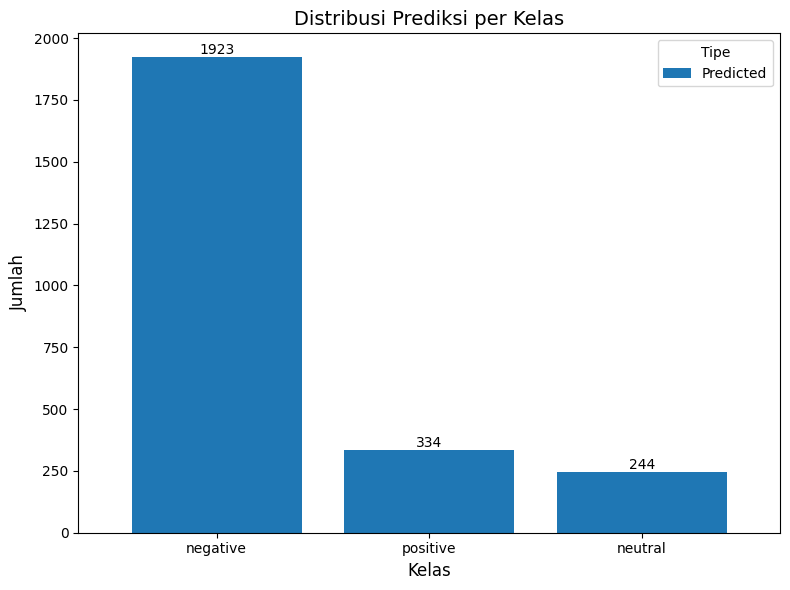

In [ ]:
# Menghitung distribusi untuk data aktual dan prediksi
actual_counts = test_df['sentiment'].value_counts()
predicted_counts = test_df['sentiment_predict'].value_counts()

# Membuat DataFrame untuk mempermudah visualisasi
summary_df = pd.DataFrame({
    # 'Actual': actual_counts,
    'Predicted': predicted_counts
}).fillna(0)  # Jika ada kelas yang tidak muncul di prediksi atau aktual

# Membuat diagram batang
ax = summary_df.plot(kind='bar', figsize=(8, 6), width=0.8)

# Menambahkan angka di atas setiap batang
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)

# Menambahkan label dan judul
title = "Distribusi Prediksi per Kelas"
plt.title(title, fontsize=14)
plt.xlabel("Kelas", fontsize=12)
plt.ylabel("Jumlah", fontsize=12)
plt.xticks(rotation=0)

# Menampilkan legenda
plt.legend(title="Tipe", fontsize=10)

# Menampilkan plot
plt.tight_layout()
plt.show()

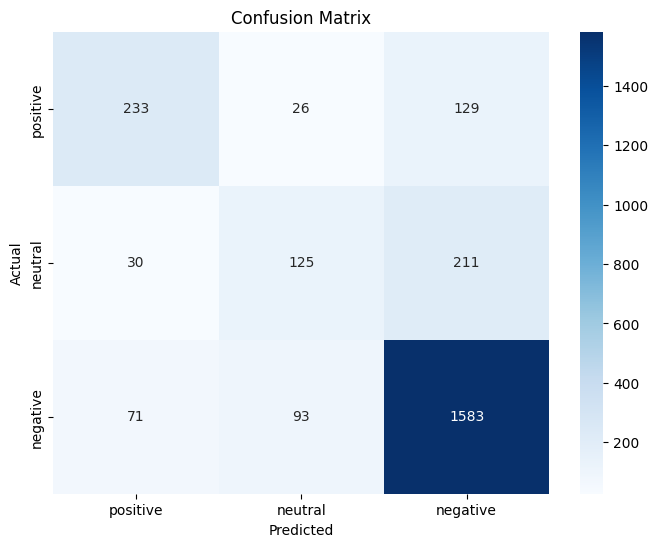


Classification Report:
              precision    recall  f1-score   support

    positive       0.82      0.91      0.86      1747
     neutral       0.51      0.34      0.41       366
    negative       0.70      0.60      0.65       388

    accuracy                           0.78      2501
   macro avg       0.68      0.62      0.64      2501
weighted avg       0.76      0.78      0.76      2501



In [ ]:
# INDOBERT EVALUATION: CONFUSION MATRIX
# Membuat Confusion Matrix untuk mengevaluasi hasil prediksi

# 'test_real' adalah label sebenarnya dari dataset uji
# 'test_pred' adalah label prediksi yang dihasilkan oleh model
test_real = test_df['sentiment']
test_pred = test_df['sentiment_predict']

# Menghitung confusion matrix menggunakan label aktual dan prediksi
# 'labels' adalah daftar label yang digunakan dalam dataset, diperoleh dari w2i.keys()
cm = confusion_matrix(test_real, test_pred, labels=list(w2i.keys()))

# Mengubah confusion matrix menjadi DataFrame untuk mempermudah visualisasi
# Baris dan kolom diberi label sesuai dengan w2i.keys() (label dataset)
df_cm = pd.DataFrame(cm, index=w2i.keys(), columns=w2i.keys())

# Visualisasi confusion matrix menggunakan heatmap dari Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues", xticklabels=w2i.keys(), yticklabels=w2i.keys())
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

# Menampilkan laporan klasifikasi untuk evaluasi model
print("\nClassification Report:")
print(classification_report(test_real, test_pred, target_names=w2i.keys()))

# Testing Skenario Learning Rate dan Epoch

#2e-5


Training with Learning Rate: 2e-06 and Epochs: 10



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7500 LR:0.00000200: 100%|██████████| 235/235 [00:51<00:00,  4.58it/s]


(Epoch 1) TRAIN LOSS:0.7500 ACC:0.71 F1:0.40 REC:0.40 PRE:0.57


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.4059 ACC:0.94 F1:0.48 REC:0.47 PRE:0.50:   1%|▏         | 1/79 [00:01<01:57,  1.51s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 1) VALID LOSS:0.6531 ACC:0.76 F1:0.59 REC:0.57 PRE:0.65


...

(Epoch 10) TRAIN LOSS:0.3222 ACC:0.89 F1:0.82 REC:0.80 PRE:0.85


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3600 ACC:0.84 F1:0.31 REC:0.28 PRE:0.33:   1%|▏         | 1/79 [00:01<01:20,  1.03s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 10) VALID LOSS:0.7054 ACC:0.76 F1:0.63 REC:0.62 PRE:0.64

Testing with Learning Rate: 2e-06 and Epochs: 10


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:07<00:00, 10.95it/s]


      index     label
0         0  negative
1         1   neutral
2         2  negative
3         3  negative
4         4  negative
...     ...       ...
2496   2496   neutral
2497   2497  negative
2498   2498  negative
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.76 F1:0.63 REC:0.61 PRE:0.65


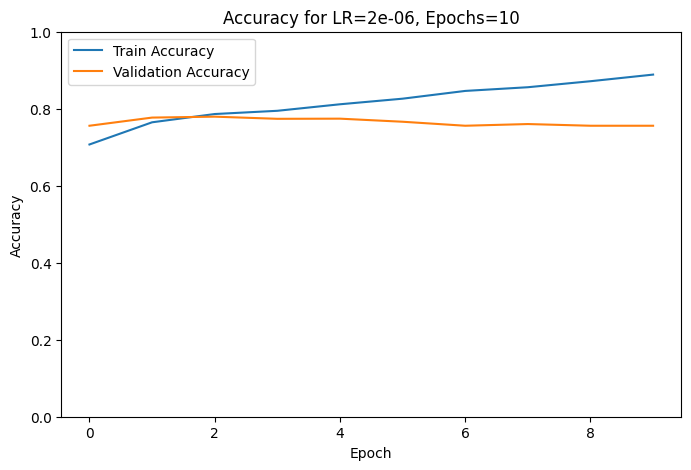

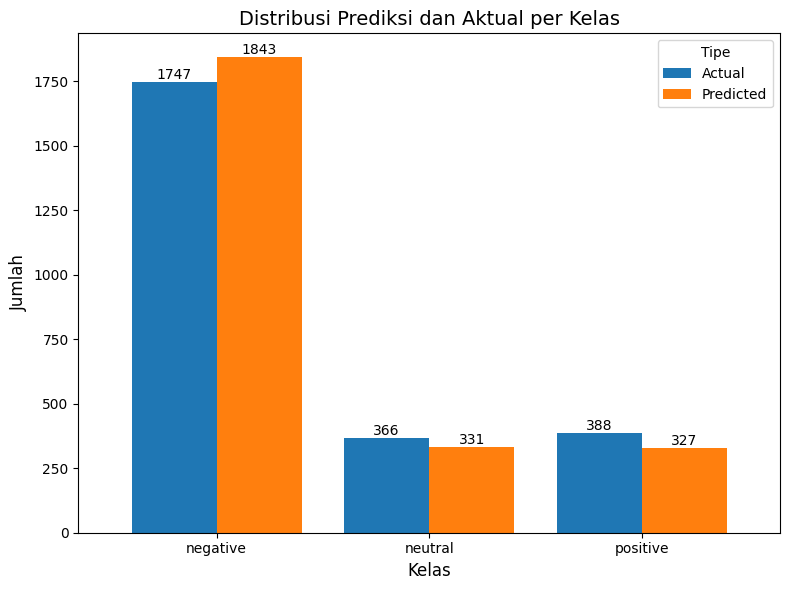

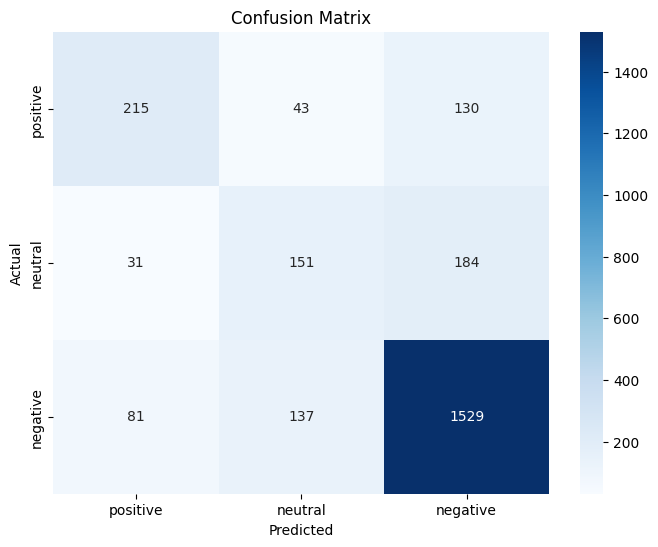


Classification Report:
              precision    recall  f1-score   support

    positive       0.83      0.88      0.85      1747
     neutral       0.46      0.41      0.43       366
    negative       0.66      0.55      0.60       388

    accuracy                           0.76      2501
   macro avg       0.65      0.61      0.63      2501
weighted avg       0.75      0.76      0.75      2501


Training with Learning Rate: 2e-06 and Epochs: 15



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7527 LR:0.00000200: 100%|██████████| 235/235 [00:51<00:00,  4.55it/s]


(Epoch 1) TRAIN LOSS:0.7527 ACC:0.70 F1:0.39 REC:0.39 PRE:0.53


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.2142 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:   3%|▎         | 2/79 [00:01<00:38,  2.01it/s]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2282 ACC:0.99 F1:0.50 REC:0.49 PRE:0.50:   3%|▎         | 2/79 [00:01<00:38,  2.01it

(Epoch 1) VALID LOSS:0.6507 ACC:0.76 F1:0.53 REC:0.50 PRE:0.70


...

(Epoch 15) TRAIN LOSS:0.1670 ACC:0.95 F1:0.91 REC:0.91 PRE:0.92


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.5311 ACC:0.81 F1:0.30 REC:0.27 PRE:0.33:   1%|▏         | 1/79 [00:01<01:29,  1.15s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 15) VALID LOSS:0.9694 ACC:0.74 F1:0.61 REC:0.61 PRE:0.61

Testing with Learning Rate: 2e-06 and Epochs: 15


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 12.38it/s]


      index     label
0         0  negative
1         1  positive
2         2   neutral
3         3  negative
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498  positive
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.74 F1:0.62 REC:0.61 PRE:0.62


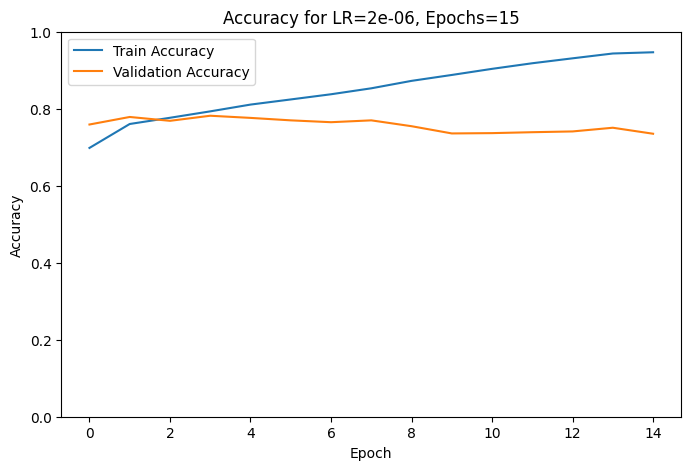

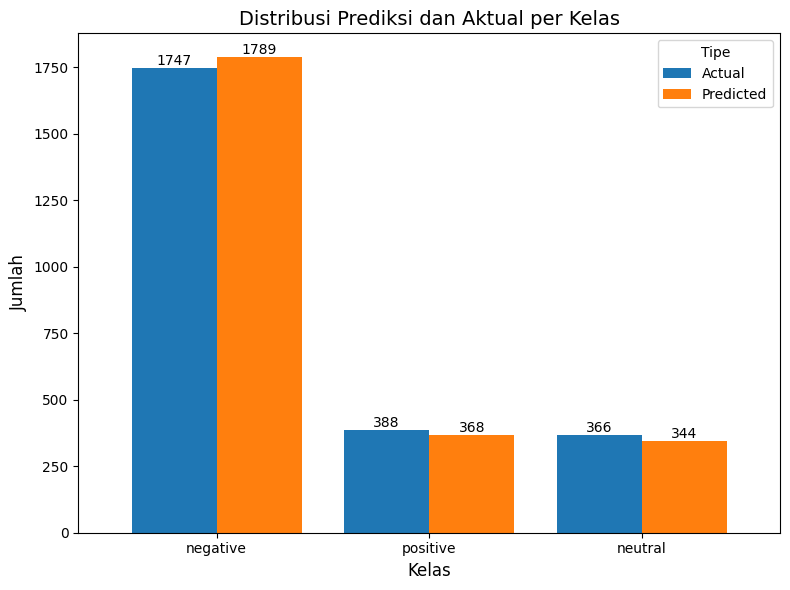

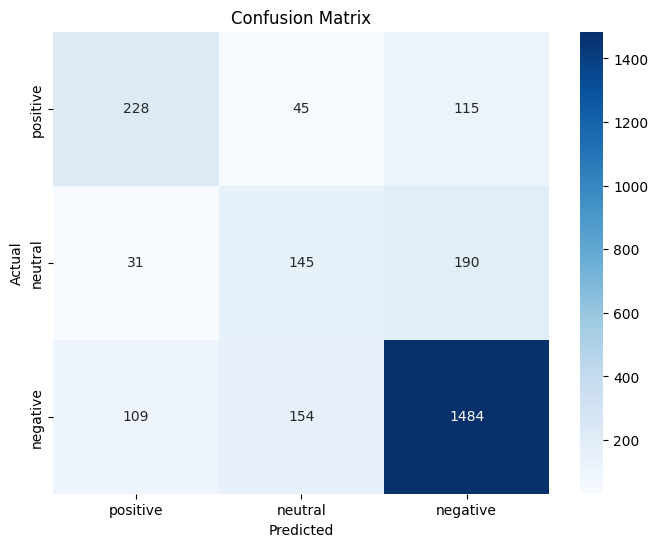


Classification Report:
              precision    recall  f1-score   support

    positive       0.83      0.85      0.84      1747
     neutral       0.42      0.40      0.41       366
    negative       0.62      0.59      0.60       388

    accuracy                           0.74      2501
   macro avg       0.62      0.61      0.62      2501
weighted avg       0.74      0.74      0.74      2501


Hyperparameter Tuning Results:
   learning_rate  epochs  train_acc   val_acc  test_acc
0       0.000002      10   0.888637  0.755795  0.757697
1       0.000002      15   0.946652  0.735012  0.742503


In [ ]:
# Define hyperparameter settings
learning_rates = [2e-5]
epochs_list = [5, 10, 15]

# Store results for each hyperparameter combination
results = []

for lr in learning_rates:
    for n_epochs in epochs_list:
        print(f"\nTraining with Learning Rate: {lr} and Epochs: {n_epochs}\n")

        # Reinitialize model and optimizer
        model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', config=config)
        model = model.cuda()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        # Reset history
        history = defaultdict(list)

        # Training and Validation
        for epoch in range(n_epochs):
            # Training loop
            model.train()
            torch.set_grad_enabled(True)

            total_train_loss = 0
            list_hyp, list_label = [], []

            train_pbar = tqdm(train_loader, leave=True, total=len(train_loader))
            for i, batch_data in enumerate(train_pbar):
                # Forward pass
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Backward pass
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                # Track metrics
                total_train_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                train_pbar.set_description(
                    f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} LR:{get_lr(optimizer):.8f}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['train_acc'].append(metrics['ACC'])

            # Validation loop
            model.eval()
            torch.set_grad_enabled(False)

            total_val_loss = 0
            list_hyp, list_label = [], []

            valid_pbar = tqdm(valid_loader, leave=True, total=len(valid_loader))
            for i, batch_data in enumerate(valid_pbar):
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Track metrics
                total_val_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                valid_pbar.set_description(
                    f"VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(document_sentiment_metrics_fn(list_hyp, list_label))}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['val_acc'].append(metrics['ACC'])

        # Testing loop
        print(f"\nTesting with Learning Rate: {lr} and Epochs: {n_epochs}")
        model.eval()
        torch.set_grad_enabled(False)

        list_hyp, list_label = [], []

        test_pbar = tqdm(test_loader, leave=True, total=len(test_loader))
        for i, batch_data in enumerate(test_pbar):
            _, batch_hyp, batch_label = forward_sequence_classification(
                model, batch_data[:-1], i2w=i2w, device='cuda'
            )
            list_hyp += batch_hyp
            list_label += batch_label

        df = pd.DataFrame({'label':list_hyp}).reset_index()
        print(df)

        # Calculate final metrics for testing
        test_metrics = document_sentiment_metrics_fn(list_hyp, list_label)
        print(f"TEST RESULTS: {metrics_to_string(test_metrics)}")

        # Save final results for this hyperparameter combination
        results.append({
            'learning_rate': lr,
            'epochs': n_epochs,
            'train_acc': history['train_acc'][-1],
            'val_acc': history['val_acc'][-1],
            'test_acc': test_metrics['ACC']
        })

        # Plot training and validation accuracy
        plt.figure(figsize=(8, 5))
        plt.plot(history['train_acc'], label='Train Accuracy')
        plt.plot(history['val_acc'], label='Validation Accuracy')
        plt.title(f'Accuracy for LR={lr}, Epochs={n_epochs}')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.ylim([0, 1])
        plt.show()

        # Load test dataset and calculate confusion matrix
        test_df = pd.read_csv(test_dataset_path, sep='\t', names=['text', 'sentiment'])  # Adjust separator as needed
        test_df['sentiment_predict'] = list_hyp

        # Menghitung distribusi untuk data aktual dan prediksi
        actual_counts = test_df['sentiment'].value_counts()
        predicted_counts = test_df['sentiment_predict'].value_counts()

        # Membuat DataFrame untuk mempermudah visualisasi
        summary_df = pd.DataFrame({
            'Actual': actual_counts,
            'Predicted': predicted_counts
        }).fillna(0)  # Jika ada kelas yang tidak muncul di prediksi atau aktual

        # Membuat diagram batang
        ax = summary_df.plot(kind='bar', figsize=(8, 6), width=0.8)

        # Menambahkan angka di atas setiap batang
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=10)

        # Menambahkan label dan judul
        title = "Distribusi Prediksi dan Aktual per Kelas"
        plt.title(title, fontsize=14)
        plt.xlabel("Kelas", fontsize=12)
        plt.ylabel("Jumlah", fontsize=12)
        plt.xticks(rotation=0)

        # Menampilkan legenda
        plt.legend(title="Tipe", fontsize=10)

        # Menampilkan plot
        plt.tight_layout()
        plt.show()

        #Evaluation
        test_real = test_df['sentiment']
        test_pred = test_df['sentiment_predict']

        # Generate Confusion Matrix
        cm = confusion_matrix(test_real, test_pred, labels=list(w2i.keys()))
        df_cm = pd.DataFrame(cm, index=w2i.keys(), columns=w2i.keys())

        # Visualize Confusion Matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues", xticklabels=w2i.keys(), yticklabels=w2i.keys())
        plt.title("Confusion Matrix")
        plt.ylabel("Actual")
        plt.xlabel("Predicted")
        plt.show()

        # Classification Report
        print("\nClassification Report:")
        print(classification_report(test_real, test_pred, target_names=w2i.keys()))

# Display summary of all results
results_df = pd.DataFrame(results)
print("\nHyperparameter Tuning Results:")
print(results_df)


#3e-5


Training with Learning Rate: 3e-05 and Epochs: 5



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.6378 LR:0.00003000: 100%|██████████| 235/235 [00:51<00:00,  4.56it/s]


(Epoch 1) TRAIN LOSS:0.6378 ACC:0.76 F1:0.57 REC:0.53 PRE:0.65


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2215 ACC:0.94 F1:0.48 REC:0.47 PRE:0.50:   1%|▏         | 1/79 [00:01<01:34,  1.21s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 1) VALID LOSS:0.5956 ACC:0.77 F1:0.63 REC:0.60 PRE:0.68


...

(Epoch 5) TRAIN LOSS:0.1436 ACC:0.95 F1:0.92 REC:0.92 PRE:0.92


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3110 ACC:0.84 F1:0.31 REC:0.28 PRE:0.33:   1%|▏         | 1/79 [00:01<01:26,  1.11s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 5) VALID LOSS:0.8836 ACC:0.73 F1:0.59 REC:0.61 PRE:0.60

Testing with Learning Rate: 3e-05 and Epochs: 5


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 11.96it/s]


      index     label
0         0  negative
1         1  positive
2         2  positive
3         3  negative
4         4  negative
...     ...       ...
2496   2496   neutral
2497   2497  negative
2498   2498  positive
2499   2499  positive
2500   2500  positive

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.72 F1:0.59 REC:0.60 PRE:0.59


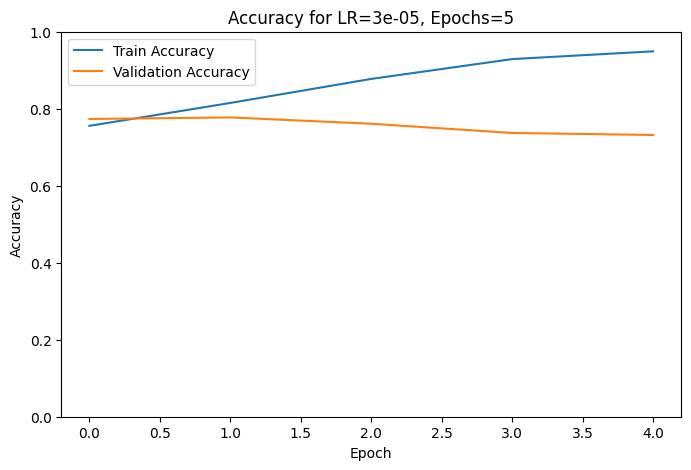

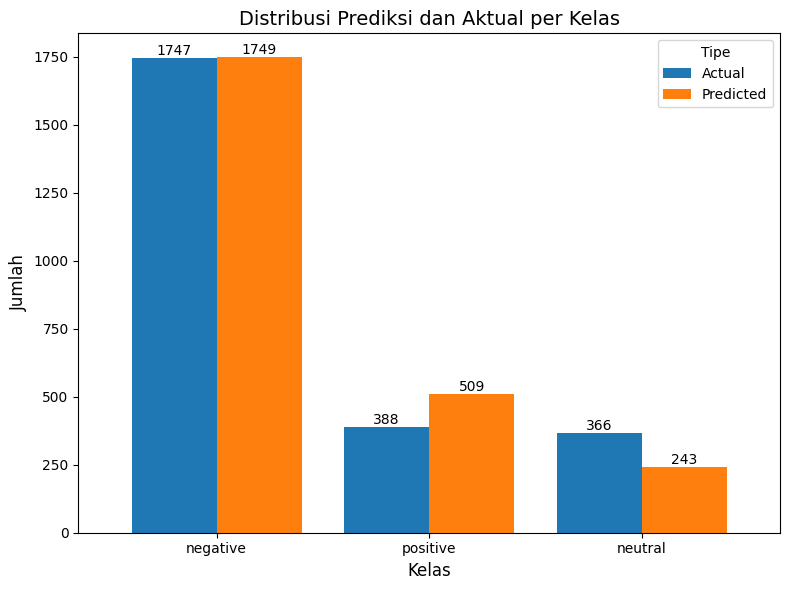

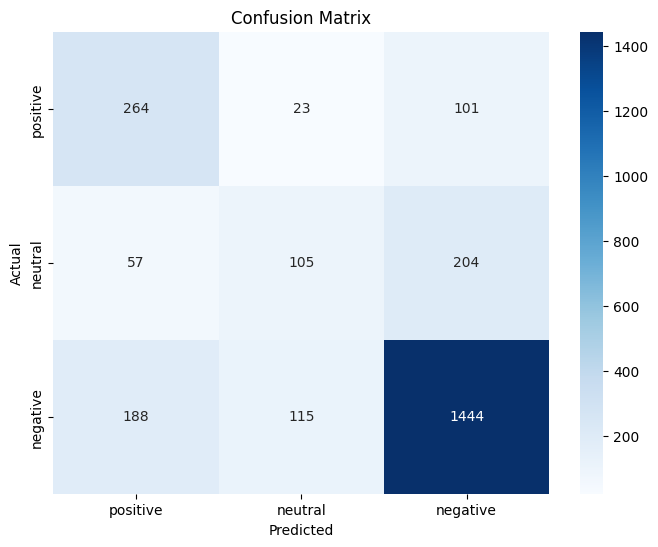


Classification Report:
              precision    recall  f1-score   support

    positive       0.83      0.83      0.83      1747
     neutral       0.43      0.29      0.34       366
    negative       0.52      0.68      0.59       388

    accuracy                           0.72      2501
   macro avg       0.59      0.60      0.59      2501
weighted avg       0.72      0.72      0.72      2501


Training with Learning Rate: 3e-05 and Epochs: 10



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.6448 LR:0.00003000: 100%|██████████| 235/235 [00:52<00:00,  4.51it/s]


(Epoch 1) TRAIN LOSS:0.6448 ACC:0.75 F1:0.55 REC:0.52 PRE:0.64


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.1423 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:   1%|▏         | 1/79 [00:01<01:28,  1.13s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.1566 ACC:0.99 F1:0.50 REC:0.49 PRE:0.50:   4%|▍         | 3/79 [00:01<00:26,  2.83it

(Epoch 1) VALID LOSS:0.6351 ACC:0.77 F1:0.59 REC:0.54 PRE:0.75


...

(Epoch 10) TRAIN LOSS:0.0644 ACC:0.98 F1:0.96 REC:0.96 PRE:0.96


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2558 ACC:0.91 F1:0.32 REC:0.30 PRE:0.33:   1%|▏         | 1/79 [00:01<01:29,  1.15s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 10) VALID LOSS:1.2864 ACC:0.76 F1:0.62 REC:0.61 PRE:0.64

Testing with Learning Rate: 3e-05 and Epochs: 10


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 12.54it/s]


      index     label
0         0  negative
1         1  negative
2         2  negative
3         3   neutral
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498  negative
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.75 F1:0.62 REC:0.61 PRE:0.64


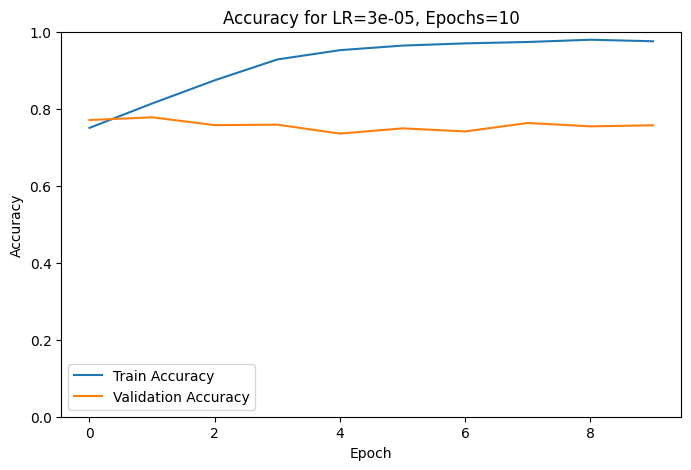

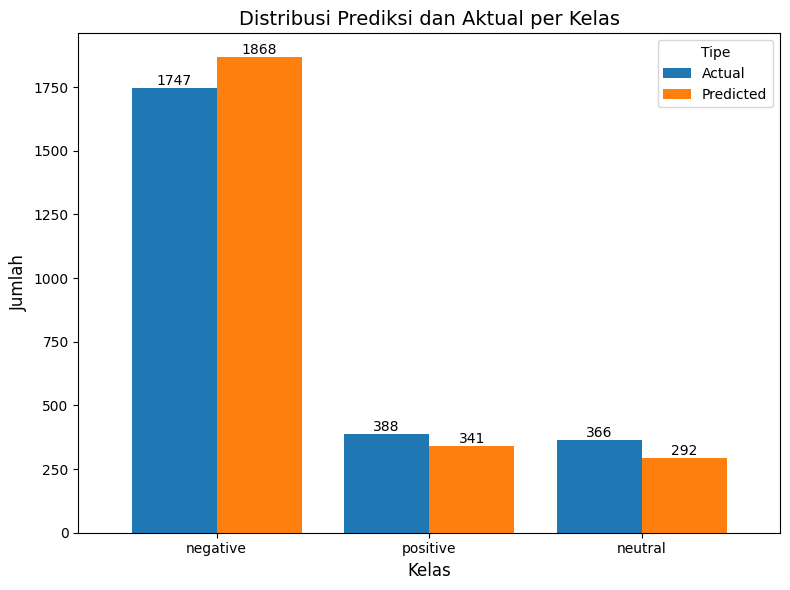

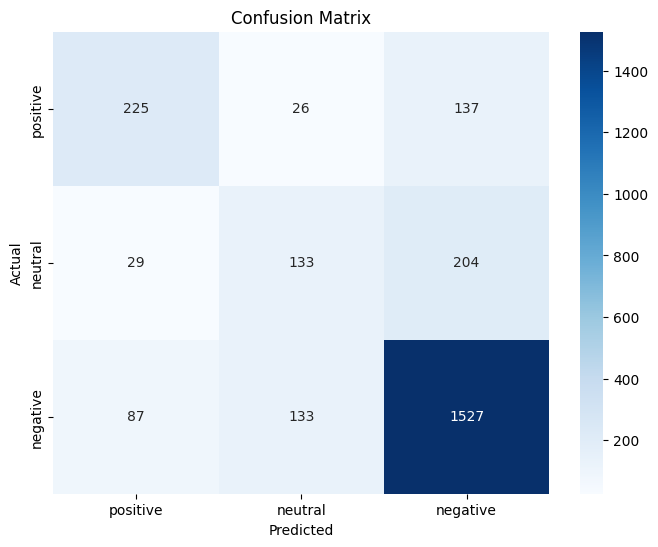


Classification Report:
              precision    recall  f1-score   support

    positive       0.82      0.87      0.84      1747
     neutral       0.46      0.36      0.40       366
    negative       0.66      0.58      0.62       388

    accuracy                           0.75      2501
   macro avg       0.64      0.61      0.62      2501
weighted avg       0.74      0.75      0.75      2501


Training with Learning Rate: 3e-05 and Epochs: 15



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.6430 LR:0.00003000: 100%|██████████| 235/235 [00:51<00:00,  4.53it/s]


(Epoch 1) TRAIN LOSS:0.6430 ACC:0.75 F1:0.56 REC:0.53 PRE:0.64


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3768 ACC:0.94 F1:0.48 REC:0.47 PRE:0.50:   1%|▏         | 1/79 [00:01<01:31,  1.17s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 1) VALID LOSS:0.5954 ACC:0.77 F1:0.63 REC:0.63 PRE:0.67


...

(Epoch 15) TRAIN LOSS:0.0534 ACC:0.98 F1:0.97 REC:0.97 PRE:0.97


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.7226 ACC:0.81 F1:0.30 REC:0.27 PRE:0.33:   1%|▏         | 1/79 [00:01<01:32,  1.18s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 15) VALID LOSS:1.4334 ACC:0.72 F1:0.60 REC:0.60 PRE:0.59

Testing with Learning Rate: 3e-05 and Epochs: 15


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 12.11it/s]


      index     label
0         0  negative
1         1   neutral
2         2  negative
3         3  negative
4         4   neutral
...     ...       ...
2496   2496   neutral
2497   2497  negative
2498   2498  negative
2499   2499  positive
2500   2500   neutral

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.71 F1:0.60 REC:0.60 PRE:0.59


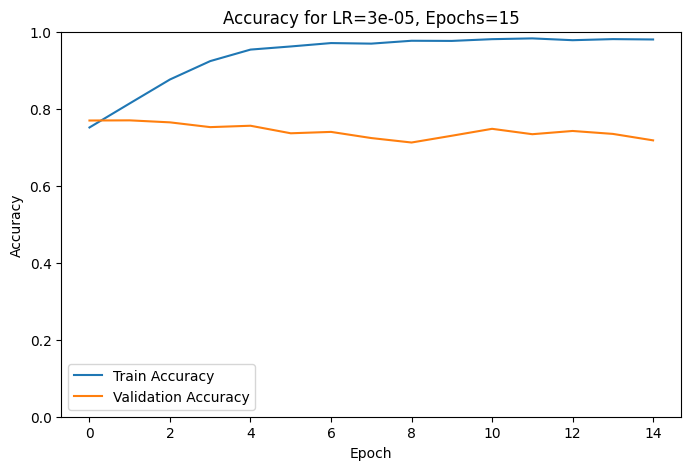

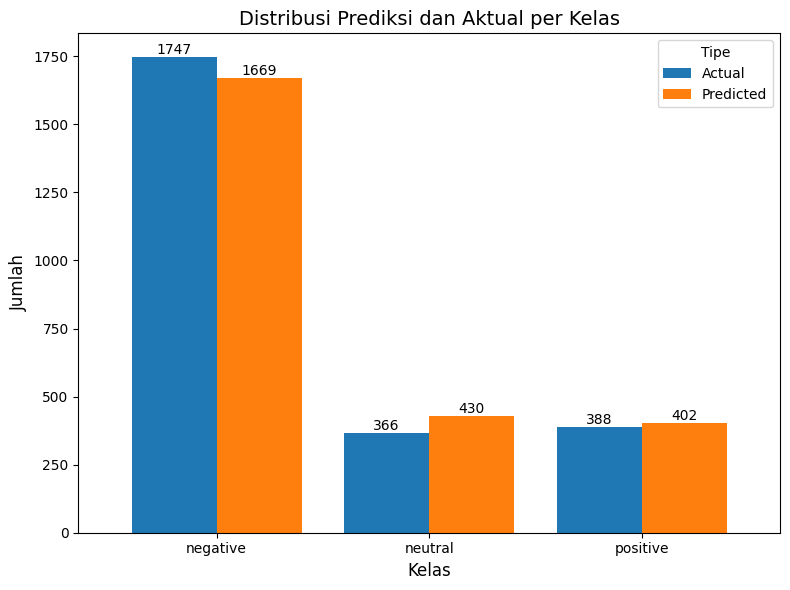

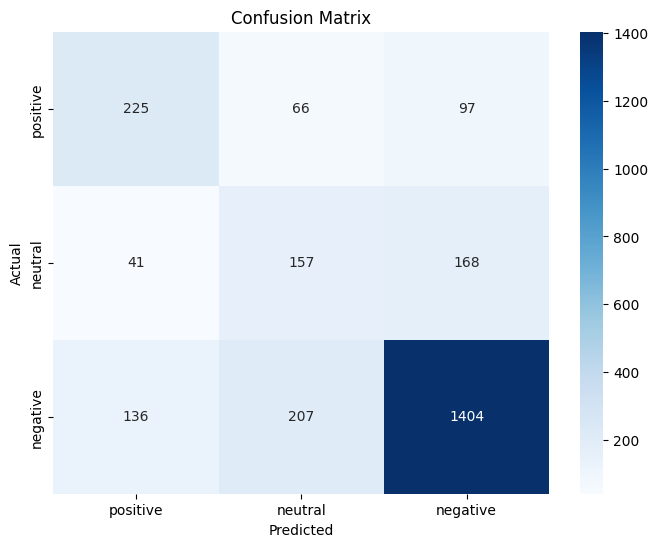


Classification Report:
              precision    recall  f1-score   support

    positive       0.84      0.80      0.82      1747
     neutral       0.37      0.43      0.39       366
    negative       0.56      0.58      0.57       388

    accuracy                           0.71      2501
   macro avg       0.59      0.60      0.60      2501
weighted avg       0.73      0.71      0.72      2501


Hyperparameter Tuning Results:
   learning_rate  epochs  train_acc   val_acc  test_acc
0        0.00003       5   0.949053  0.731815  0.724910
1        0.00003      10   0.975193  0.756994  0.753699
2        0.00003      15   0.979861  0.717826  0.714114


In [ ]:
# Define hyperparameter settings
learning_rates = [3e-5]
epochs_list = [5, 10, 15]

# Store results for each hyperparameter combination
results = []

for lr in learning_rates:
    for n_epochs in epochs_list:
        print(f"\nTraining with Learning Rate: {lr} and Epochs: {n_epochs}\n")

        # Reinitialize model and optimizer
        model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', config=config)
        model = model.cuda()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        # Reset history
        history = defaultdict(list)

        # Training and Validation
        for epoch in range(n_epochs):
            # Training loop
            model.train()
            torch.set_grad_enabled(True)

            total_train_loss = 0
            list_hyp, list_label = [], []

            train_pbar = tqdm(train_loader, leave=True, total=len(train_loader))
            for i, batch_data in enumerate(train_pbar):
                # Forward pass
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Backward pass
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                # Track metrics
                total_train_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                train_pbar.set_description(
                    f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} LR:{get_lr(optimizer):.8f}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['train_acc'].append(metrics['ACC'])

            # Validation loop
            model.eval()
            torch.set_grad_enabled(False)

            total_val_loss = 0
            list_hyp, list_label = [], []

            valid_pbar = tqdm(valid_loader, leave=True, total=len(valid_loader))
            for i, batch_data in enumerate(valid_pbar):
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Track metrics
                total_val_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                valid_pbar.set_description(
                    f"VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(document_sentiment_metrics_fn(list_hyp, list_label))}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['val_acc'].append(metrics['ACC'])

        # Testing loop
        print(f"\nTesting with Learning Rate: {lr} and Epochs: {n_epochs}")
        model.eval()
        torch.set_grad_enabled(False)

        list_hyp, list_label = [], []

        test_pbar = tqdm(test_loader, leave=True, total=len(test_loader))
        for i, batch_data in enumerate(test_pbar):
            _, batch_hyp, batch_label = forward_sequence_classification(
                model, batch_data[:-1], i2w=i2w, device='cuda'
            )
            list_hyp += batch_hyp
            list_label += batch_label

        df = pd.DataFrame({'label':list_hyp}).reset_index()
        print(df)

        # Calculate final metrics for testing
        test_metrics = document_sentiment_metrics_fn(list_hyp, list_label)
        print(f"TEST RESULTS: {metrics_to_string(test_metrics)}")

        # Save final results for this hyperparameter combination
        results.append({
            'learning_rate': lr,
            'epochs': n_epochs,
            'train_acc': history['train_acc'][-1],
            'val_acc': history['val_acc'][-1],
            'test_acc': test_metrics['ACC']
        })

        # Plot training and validation accuracy
        plt.figure(figsize=(8, 5))
        plt.plot(history['train_acc'], label='Train Accuracy')
        plt.plot(history['val_acc'], label='Validation Accuracy')
        plt.title(f'Accuracy for LR={lr}, Epochs={n_epochs}')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.ylim([0, 1])
        plt.show()

        # Load test dataset and calculate confusion matrix
        test_df = pd.read_csv(test_dataset_path, sep='\t', names=['text', 'sentiment'])  # Adjust separator as needed
        test_df['sentiment_predict'] = list_hyp

        # Menghitung distribusi untuk data aktual dan prediksi
        actual_counts = test_df['sentiment'].value_counts()
        predicted_counts = test_df['sentiment_predict'].value_counts()

        # Membuat DataFrame untuk mempermudah visualisasi
        summary_df = pd.DataFrame({
            'Actual': actual_counts,
            'Predicted': predicted_counts
        }).fillna(0)  # Jika ada kelas yang tidak muncul di prediksi atau aktual

        # Membuat diagram batang
        ax = summary_df.plot(kind='bar', figsize=(8, 6), width=0.8)

        # Menambahkan angka di atas setiap batang
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=10)

        # Menambahkan label dan judul
        title = "Distribusi Prediksi dan Aktual per Kelas"
        plt.title(title, fontsize=14)
        plt.xlabel("Kelas", fontsize=12)
        plt.ylabel("Jumlah", fontsize=12)
        plt.xticks(rotation=0)

        # Menampilkan legenda
        plt.legend(title="Tipe", fontsize=10)

        # Menampilkan plot
        plt.tight_layout()
        plt.show()

        #Evaluation
        test_real = test_df['sentiment']
        test_pred = test_df['sentiment_predict']

        # Generate Confusion Matrix
        cm = confusion_matrix(test_real, test_pred, labels=list(w2i.keys()))
        df_cm = pd.DataFrame(cm, index=w2i.keys(), columns=w2i.keys())

        # Visualize Confusion Matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues", xticklabels=w2i.keys(), yticklabels=w2i.keys())
        plt.title("Confusion Matrix")
        plt.ylabel("Actual")
        plt.xlabel("Predicted")
        plt.show()

        # Classification Report
        print("\nClassification Report:")
        print(classification_report(test_real, test_pred, target_names=w2i.keys()))

# Display summary of all results
results_df = pd.DataFrame(results)
print("\nHyperparameter Tuning Results:")
print(results_df)


#2e-6


Training with Learning Rate: 2e-06 and Epochs: 5



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7307 LR:0.00000200: 100%|██████████| 235/235 [00:51<00:00,  4.56it/s]


(Epoch 1) TRAIN LOSS:0.7307 ACC:0.71 F1:0.42 REC:0.41 PRE:0.58


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.2592 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:   3%|▎         | 2/79 [00:01<01:03,  1.21it/s]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2775 ACC:0.98 F1:0.49 REC:0.49 PRE:0.50:   3%|▎         | 2/79 [00:02<01:03,  1.21it

(Epoch 1) VALID LOSS:0.6425 ACC:0.76 F1:0.56 REC:0.54 PRE:0.68


...

(Epoch 5) TRAIN LOSS:0.4989 ACC:0.81 F1:0.69 REC:0.66 PRE:0.75


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2197 ACC:0.94 F1:0.32 REC:0.31 PRE:0.33:   1%|▏         | 1/79 [00:01<01:30,  1.15s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 5) VALID LOSS:0.5982 ACC:0.78 F1:0.64 REC:0.61 PRE:0.69

Testing with Learning Rate: 2e-06 and Epochs: 5


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 12.09it/s]


      index     label
0         0  negative
1         1   neutral
2         2  negative
3         3  negative
4         4  negative
...     ...       ...
2496   2496  positive
2497   2497  negative
2498   2498  negative
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.77 F1:0.63 REC:0.59 PRE:0.68


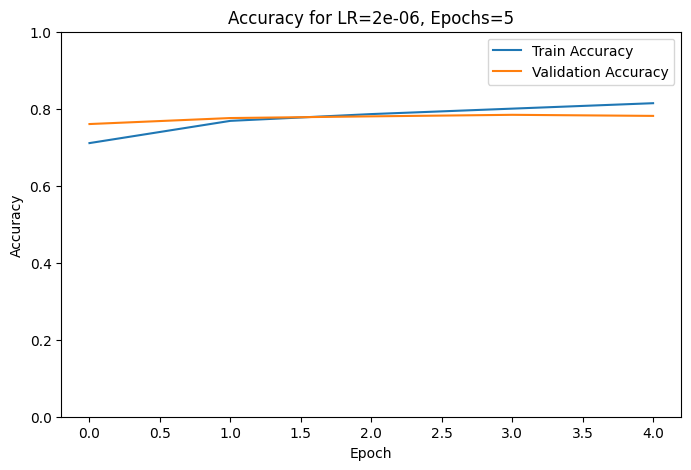

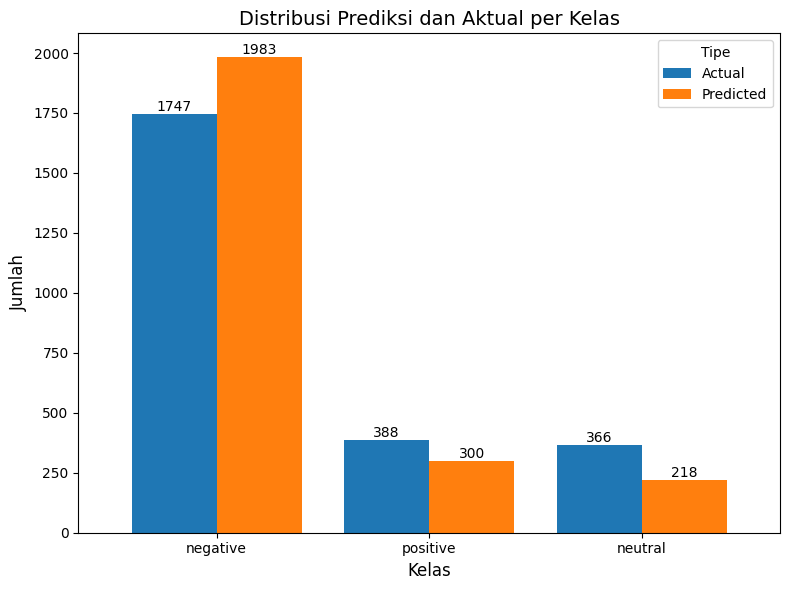

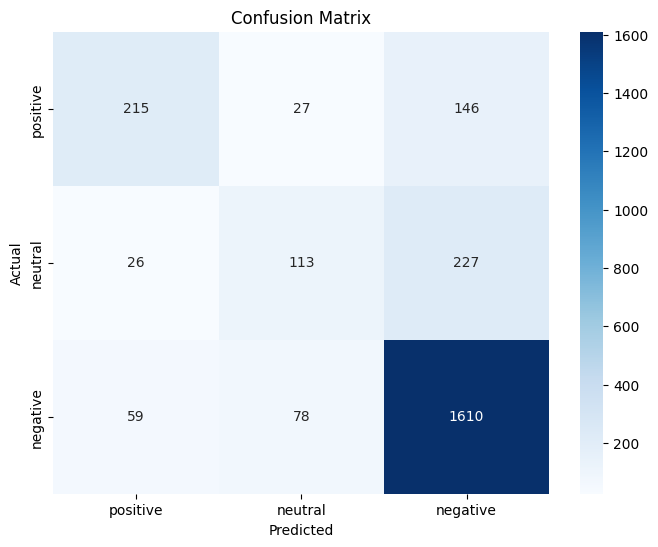


Classification Report:
              precision    recall  f1-score   support

    positive       0.81      0.92      0.86      1747
     neutral       0.52      0.31      0.39       366
    negative       0.72      0.55      0.62       388

    accuracy                           0.77      2501
   macro avg       0.68      0.59      0.63      2501
weighted avg       0.75      0.77      0.76      2501


Training with Learning Rate: 2e-06 and Epochs: 10



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7484 LR:0.00000200: 100%|██████████| 235/235 [00:51<00:00,  4.55it/s]


(Epoch 1) TRAIN LOSS:0.7484 ACC:0.70 F1:0.40 REC:0.39 PRE:0.56


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3667 ACC:0.94 F1:0.32 REC:0.31 PRE:0.33:   1%|▏         | 1/79 [00:01<01:40,  1.29s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 1) VALID LOSS:0.6460 ACC:0.76 F1:0.58 REC:0.57 PRE:0.66


...

(Epoch 10) TRAIN LOSS:0.3190 ACC:0.89 F1:0.83 REC:0.81 PRE:0.85


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3461 ACC:0.84 F1:0.31 REC:0.28 PRE:0.33:   1%|▏         | 1/79 [00:01<02:18,  1.77s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 10) VALID LOSS:0.7103 ACC:0.76 F1:0.63 REC:0.62 PRE:0.66

Testing with Learning Rate: 2e-06 and Epochs: 10


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 12.07it/s]


      index     label
0         0  negative
1         1  negative
2         2  positive
3         3  negative
4         4  negative
...     ...       ...
2496   2496   neutral
2497   2497  negative
2498   2498  positive
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.76 F1:0.62 REC:0.60 PRE:0.65


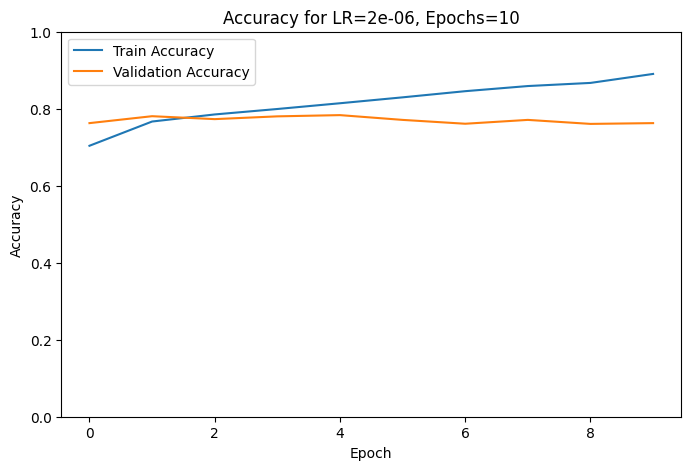

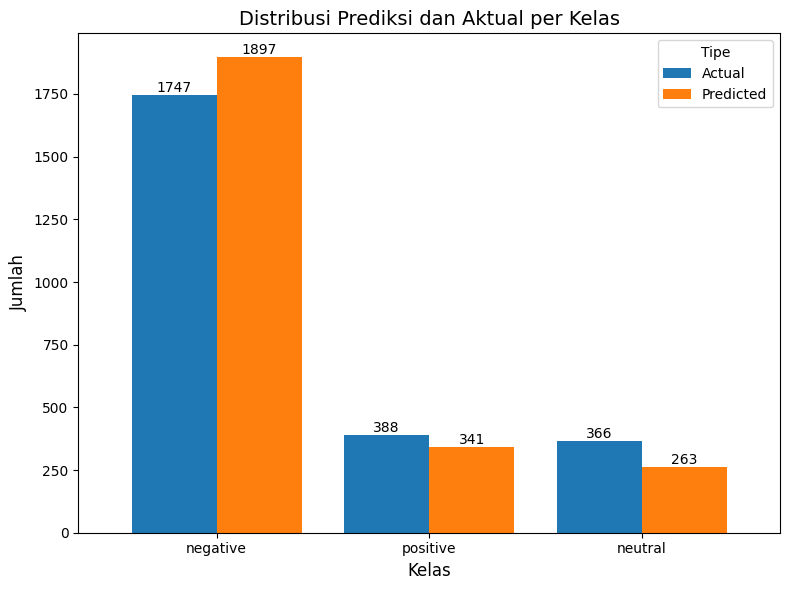

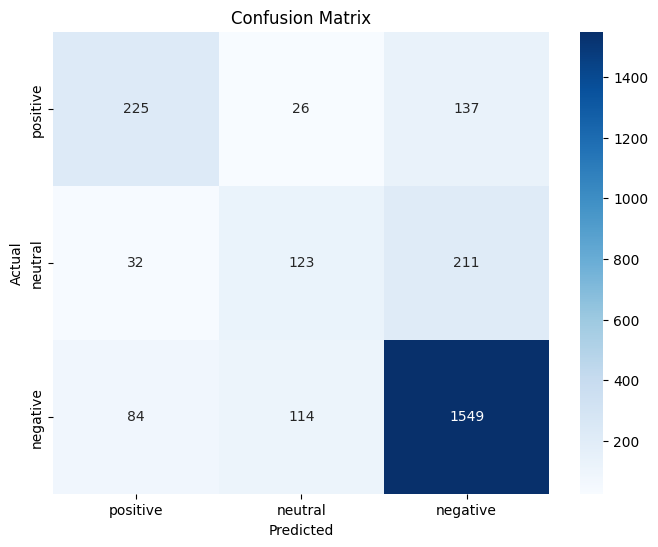


Classification Report:
              precision    recall  f1-score   support

    positive       0.82      0.89      0.85      1747
     neutral       0.47      0.34      0.39       366
    negative       0.66      0.58      0.62       388

    accuracy                           0.76      2501
   macro avg       0.65      0.60      0.62      2501
weighted avg       0.74      0.76      0.75      2501


Training with Learning Rate: 2e-06 and Epochs: 15



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7044 LR:0.00000200: 100%|██████████| 235/235 [00:52<00:00,  4.47it/s]


(Epoch 1) TRAIN LOSS:0.7044 ACC:0.73 F1:0.44 REC:0.43 PRE:0.65


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.2495 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:   3%|▎         | 2/79 [00:02<01:13,  1.05it/s]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2592 ACC:0.98 F1:0.33 REC:0.33 PRE:0.33:   4%|▍         | 3/79 [00:02<00:43,  1.75it

(Epoch 1) VALID LOSS:0.6311 ACC:0.77 F1:0.57 REC:0.54 PRE:0.71


...

(Epoch 15) TRAIN LOSS:0.1493 ACC:0.95 F1:0.92 REC:0.91 PRE:0.93


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.5589 ACC:0.78 F1:0.29 REC:0.26 PRE:0.33:   1%|▏         | 1/79 [00:01<01:41,  1.30s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 15) VALID LOSS:0.9689 ACC:0.74 F1:0.61 REC:0.60 PRE:0.61

Testing with Learning Rate: 2e-06 and Epochs: 15


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 11.96it/s]


      index     label
0         0  negative
1         1  positive
2         2   neutral
3         3  negative
4         4  negative
...     ...       ...
2496   2496  positive
2497   2497  negative
2498   2498  negative
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.76 F1:0.63 REC:0.62 PRE:0.65


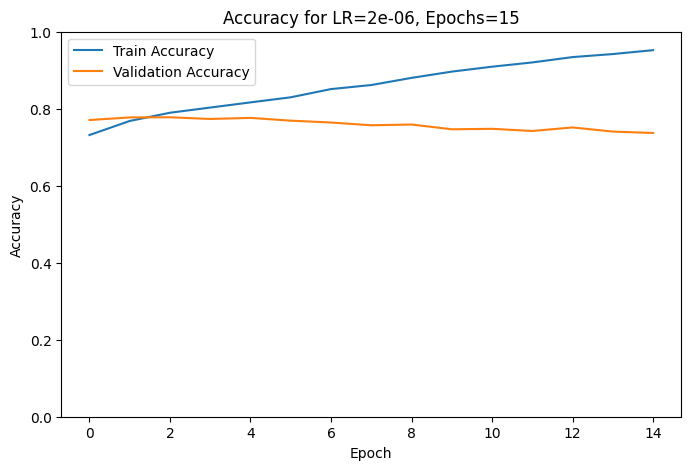

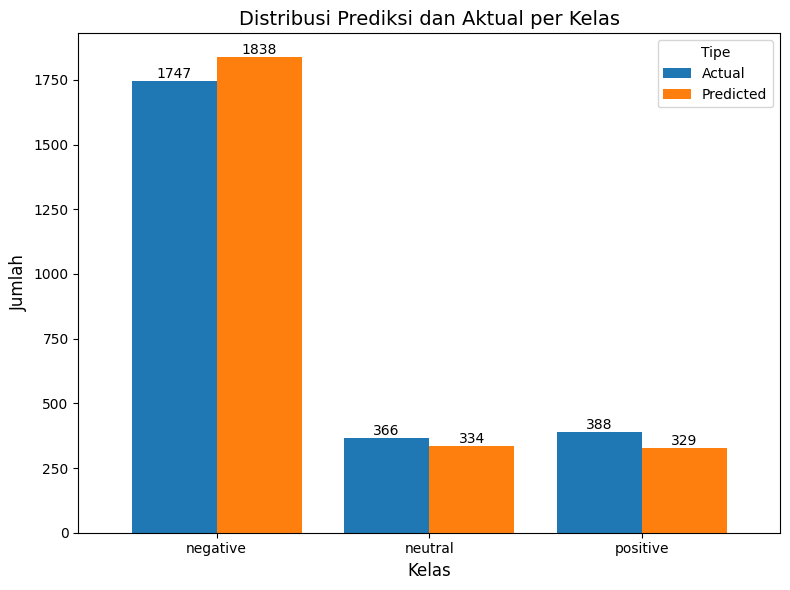

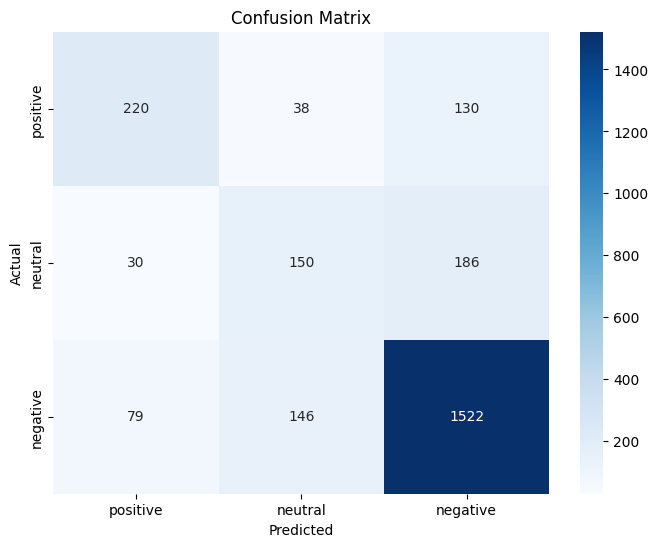


Classification Report:
              precision    recall  f1-score   support

    positive       0.83      0.87      0.85      1747
     neutral       0.45      0.41      0.43       366
    negative       0.67      0.57      0.61       388

    accuracy                           0.76      2501
   macro avg       0.65      0.62      0.63      2501
weighted avg       0.75      0.76      0.75      2501


Hyperparameter Tuning Results:
   learning_rate  epochs  train_acc   val_acc  test_acc
0       0.000002       5   0.814350  0.781375  0.774890
1       0.000002      10   0.890371  0.762590  0.758497
2       0.000002      15   0.952121  0.737010  0.756497


In [ ]:
# Define hyperparameter settings
learning_rates = [2e-6]
epochs_list = [5, 10, 15]

# Store results for each hyperparameter combination
results = []

for lr in learning_rates:
    for n_epochs in epochs_list:
        print(f"\nTraining with Learning Rate: {lr} and Epochs: {n_epochs}\n")

        # Reinitialize model and optimizer
        model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', config=config)
        model = model.cuda()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        # Reset history
        history = defaultdict(list)

        # Training and Validation
        for epoch in range(n_epochs):
            # Training loop
            model.train()
            torch.set_grad_enabled(True)

            total_train_loss = 0
            list_hyp, list_label = [], []

            train_pbar = tqdm(train_loader, leave=True, total=len(train_loader))
            for i, batch_data in enumerate(train_pbar):
                # Forward pass
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Backward pass
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                # Track metrics
                total_train_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                train_pbar.set_description(
                    f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} LR:{get_lr(optimizer):.8f}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['train_acc'].append(metrics['ACC'])

            # Validation loop
            model.eval()
            torch.set_grad_enabled(False)

            total_val_loss = 0
            list_hyp, list_label = [], []

            valid_pbar = tqdm(valid_loader, leave=True, total=len(valid_loader))
            for i, batch_data in enumerate(valid_pbar):
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Track metrics
                total_val_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                valid_pbar.set_description(
                    f"VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(document_sentiment_metrics_fn(list_hyp, list_label))}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['val_acc'].append(metrics['ACC'])

        # Testing loop
        print(f"\nTesting with Learning Rate: {lr} and Epochs: {n_epochs}")
        model.eval()
        torch.set_grad_enabled(False)

        list_hyp, list_label = [], []

        test_pbar = tqdm(test_loader, leave=True, total=len(test_loader))
        for i, batch_data in enumerate(test_pbar):
            _, batch_hyp, batch_label = forward_sequence_classification(
                model, batch_data[:-1], i2w=i2w, device='cuda'
            )
            list_hyp += batch_hyp
            list_label += batch_label

        df = pd.DataFrame({'label':list_hyp}).reset_index()
        print(df)

        # Calculate final metrics for testing
        test_metrics = document_sentiment_metrics_fn(list_hyp, list_label)
        print(f"TEST RESULTS: {metrics_to_string(test_metrics)}")

        # Save final results for this hyperparameter combination
        results.append({
            'learning_rate': lr,
            'epochs': n_epochs,
            'train_acc': history['train_acc'][-1],
            'val_acc': history['val_acc'][-1],
            'test_acc': test_metrics['ACC']
        })

        # Plot training and validation accuracy
        plt.figure(figsize=(8, 5))
        plt.plot(history['train_acc'], label='Train Accuracy')
        plt.plot(history['val_acc'], label='Validation Accuracy')
        plt.title(f'Accuracy for LR={lr}, Epochs={n_epochs}')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.ylim([0, 1])
        plt.show()

        # Load test dataset and calculate confusion matrix
        test_df = pd.read_csv(test_dataset_path, sep='\t', names=['text', 'sentiment'])  # Adjust separator as needed
        test_df['sentiment_predict'] = list_hyp

        # Menghitung distribusi untuk data aktual dan prediksi
        actual_counts = test_df['sentiment'].value_counts()
        predicted_counts = test_df['sentiment_predict'].value_counts()

        # Membuat DataFrame untuk mempermudah visualisasi
        summary_df = pd.DataFrame({
            'Actual': actual_counts,
            'Predicted': predicted_counts
        }).fillna(0)  # Jika ada kelas yang tidak muncul di prediksi atau aktual

        # Membuat diagram batang
        ax = summary_df.plot(kind='bar', figsize=(8, 6), width=0.8)

        # Menambahkan angka di atas setiap batang
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=10)

        # Menambahkan label dan judul
        title = "Distribusi Prediksi dan Aktual per Kelas"
        plt.title(title, fontsize=14)
        plt.xlabel("Kelas", fontsize=12)
        plt.ylabel("Jumlah", fontsize=12)
        plt.xticks(rotation=0)

        # Menampilkan legenda
        plt.legend(title="Tipe", fontsize=10)

        # Menampilkan plot
        plt.tight_layout()
        plt.show()

        #Evaluation
        test_real = test_df['sentiment']
        test_pred = test_df['sentiment_predict']

        # Generate Confusion Matrix
        cm = confusion_matrix(test_real, test_pred, labels=list(w2i.keys()))
        df_cm = pd.DataFrame(cm, index=w2i.keys(), columns=w2i.keys())

        # Visualize Confusion Matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues", xticklabels=w2i.keys(), yticklabels=w2i.keys())
        plt.title("Confusion Matrix")
        plt.ylabel("Actual")
        plt.xlabel("Predicted")
        plt.show()

        # Classification Report
        print("\nClassification Report:")
        print(classification_report(test_real, test_pred, target_names=w2i.keys()))

# Display summary of all results
results_df = pd.DataFrame(results)
print("\nHyperparameter Tuning Results:")
print(results_df)


#3e-6


Training with Learning Rate: 3e-06 and Epochs: 5



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7226 LR:0.00000300: 100%|██████████| 235/235 [00:52<00:00,  4.50it/s]


(Epoch 1) TRAIN LOSS:0.7226 ACC:0.71 F1:0.44 REC:0.43 PRE:0.57


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2876 ACC:0.97 F1:0.49 REC:0.48 PRE:0.50:   1%|▏         | 1/79 [00:02<02:51,  2.20s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 1) VALID LOSS:0.6247 ACC:0.77 F1:0.58 REC:0.55 PRE:0.70


...

(Epoch 5) TRAIN LOSS:0.4420 ACC:0.84 F1:0.74 REC:0.71 PRE:0.78


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.1969 ACC:0.94 F1:0.32 REC:0.31 PRE:0.33:   1%|▏         | 1/79 [00:02<02:50,  2.19s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 5) VALID LOSS:0.6290 ACC:0.77 F1:0.63 REC:0.59 PRE:0.69

Testing with Learning Rate: 3e-06 and Epochs: 5


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 12.03it/s]


      index     label
0         0  negative
1         1   neutral
2         2  negative
3         3  negative
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498   neutral
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.78 F1:0.64 REC:0.60 PRE:0.71


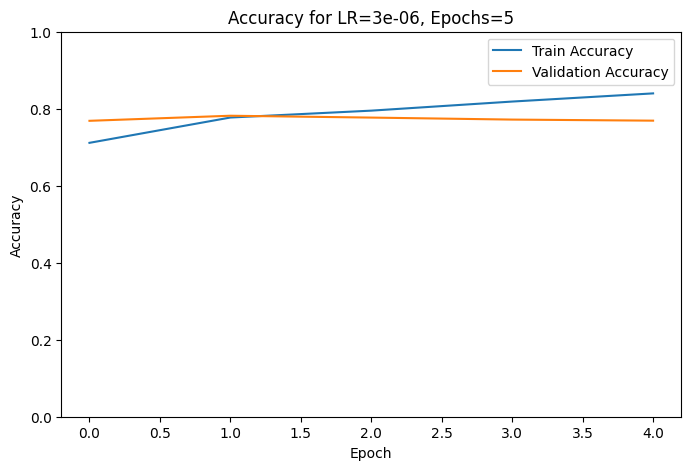

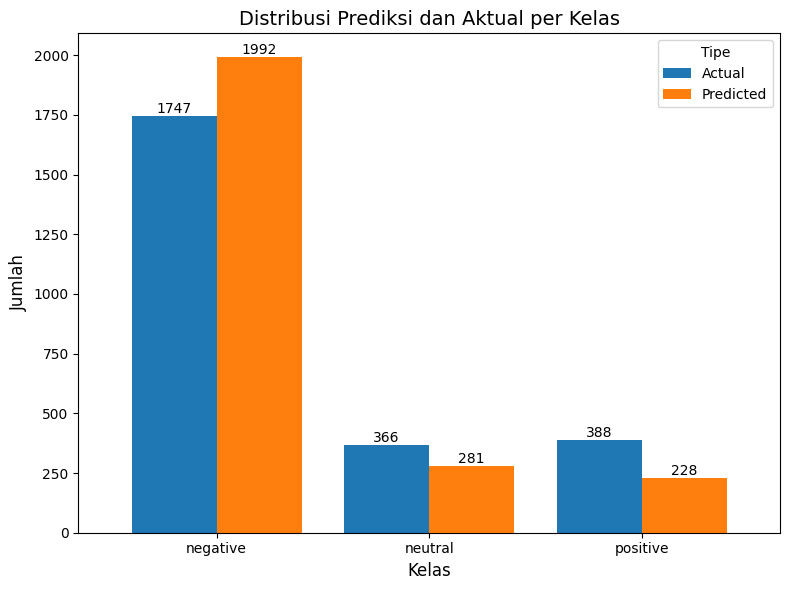

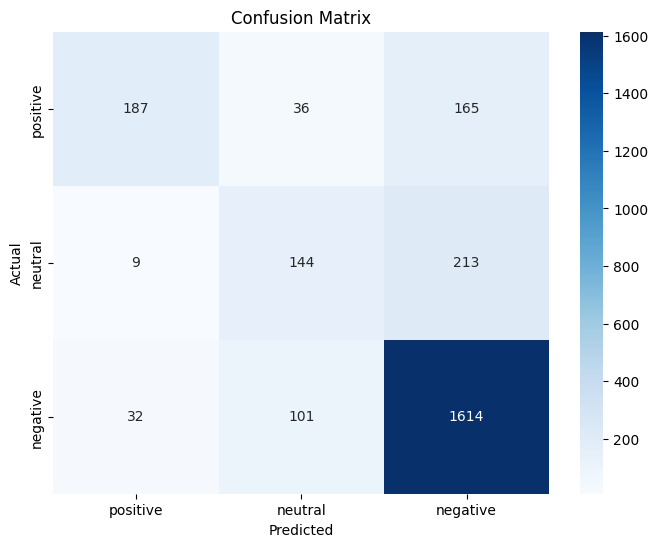


Classification Report:
              precision    recall  f1-score   support

    positive       0.81      0.92      0.86      1747
     neutral       0.51      0.39      0.45       366
    negative       0.82      0.48      0.61       388

    accuracy                           0.78      2501
   macro avg       0.71      0.60      0.64      2501
weighted avg       0.77      0.78      0.76      2501


Training with Learning Rate: 3e-06 and Epochs: 10



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7125 LR:0.00000300: 100%|██████████| 235/235 [00:52<00:00,  4.51it/s]


(Epoch 1) TRAIN LOSS:0.7125 ACC:0.72 F1:0.45 REC:0.43 PRE:0.59


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2791 ACC:0.97 F1:0.49 REC:0.48 PRE:0.50:   1%|▏         | 1/79 [00:01<01:42,  1.31s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 1) VALID LOSS:0.6201 ACC:0.77 F1:0.58 REC:0.56 PRE:0.70


...

(Epoch 10) TRAIN LOSS:0.1803 ACC:0.94 F1:0.91 REC:0.90 PRE:0.91


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3947 ACC:0.88 F1:0.31 REC:0.29 PRE:0.33:   1%|▏         | 1/79 [00:01<01:47,  1.38s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 10) VALID LOSS:0.8517 ACC:0.75 F1:0.61 REC:0.59 PRE:0.63

Testing with Learning Rate: 3e-06 and Epochs: 10


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 11.66it/s]


      index     label
0         0  negative
1         1  positive
2         2  positive
3         3  negative
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498  negative
2499   2499  positive
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.75 F1:0.61 REC:0.59 PRE:0.64


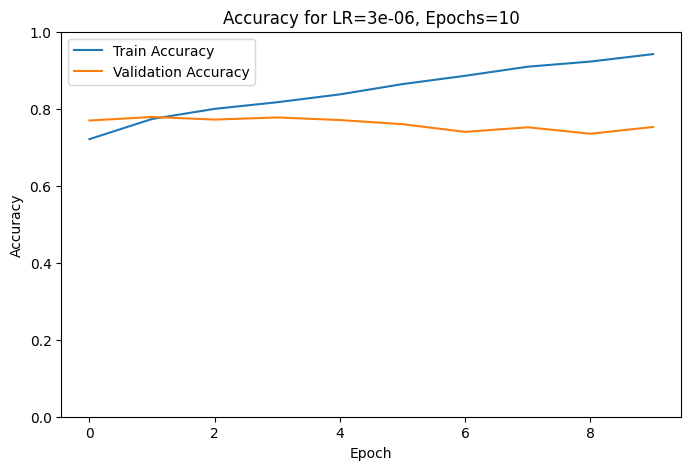

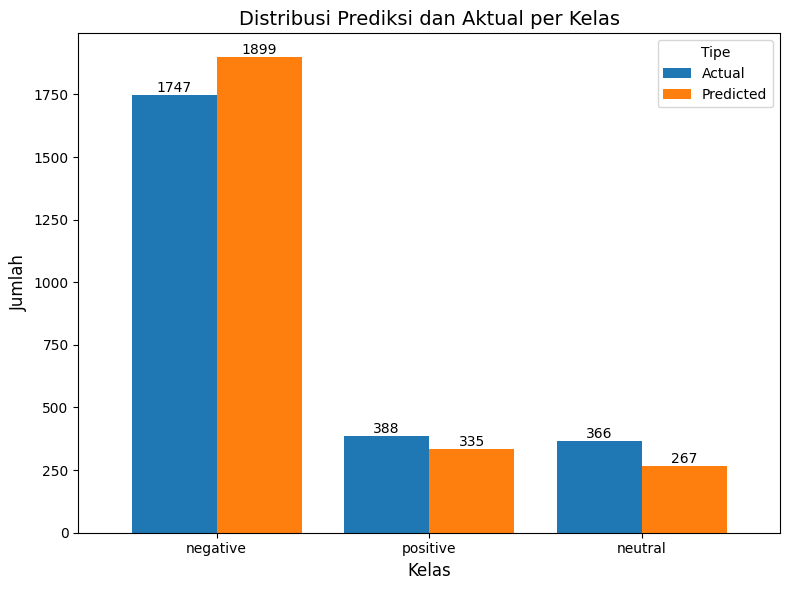

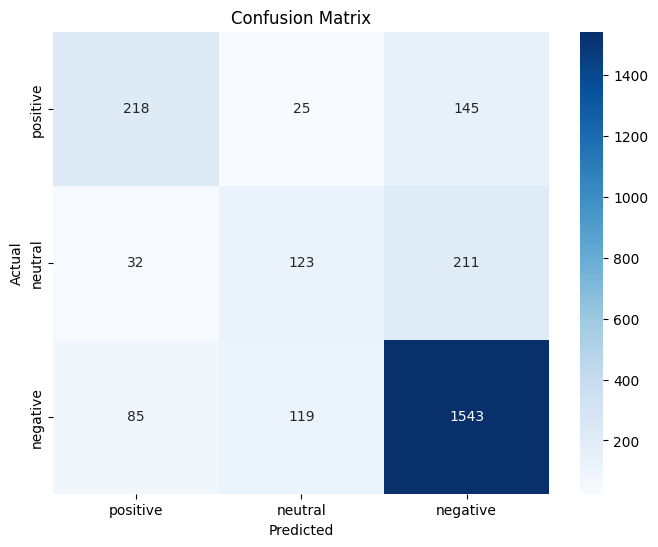


Classification Report:
              precision    recall  f1-score   support

    positive       0.81      0.88      0.85      1747
     neutral       0.46      0.34      0.39       366
    negative       0.65      0.56      0.60       388

    accuracy                           0.75      2501
   macro avg       0.64      0.59      0.61      2501
weighted avg       0.74      0.75      0.74      2501


Training with Learning Rate: 3e-06 and Epochs: 15



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.7061 LR:0.00000300: 100%|██████████| 235/235 [00:51<00:00,  4.54it/s]


(Epoch 1) TRAIN LOSS:0.7061 ACC:0.72 F1:0.46 REC:0.44 PRE:0.60


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2958 ACC:0.97 F1:0.49 REC:0.48 PRE:0.50:   1%|▏         | 1/79 [00:01<01:46,  1.36s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 1) VALID LOSS:0.6131 ACC:0.77 F1:0.62 REC:0.60 PRE:0.68


...

(Epoch 15) TRAIN LOSS:0.0776 ACC:0.97 F1:0.96 REC:0.96 PRE:0.95


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.6290 ACC:0.88 F1:0.31 REC:0.29 PRE:0.33:   1%|▏         | 1/79 [00:01<01:48,  1.39s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 15) VALID LOSS:1.1856 ACC:0.74 F1:0.61 REC:0.60 PRE:0.61

Testing with Learning Rate: 3e-06 and Epochs: 15


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 11.78it/s]


      index     label
0         0  negative
1         1  positive
2         2   neutral
3         3   neutral
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498  negative
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.75 F1:0.61 REC:0.61 PRE:0.63


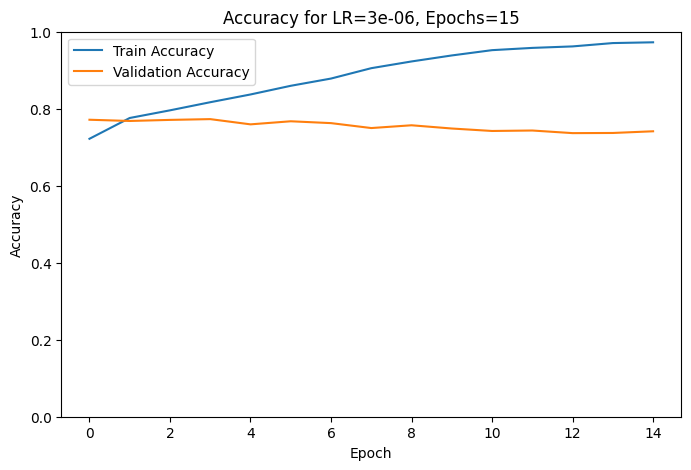

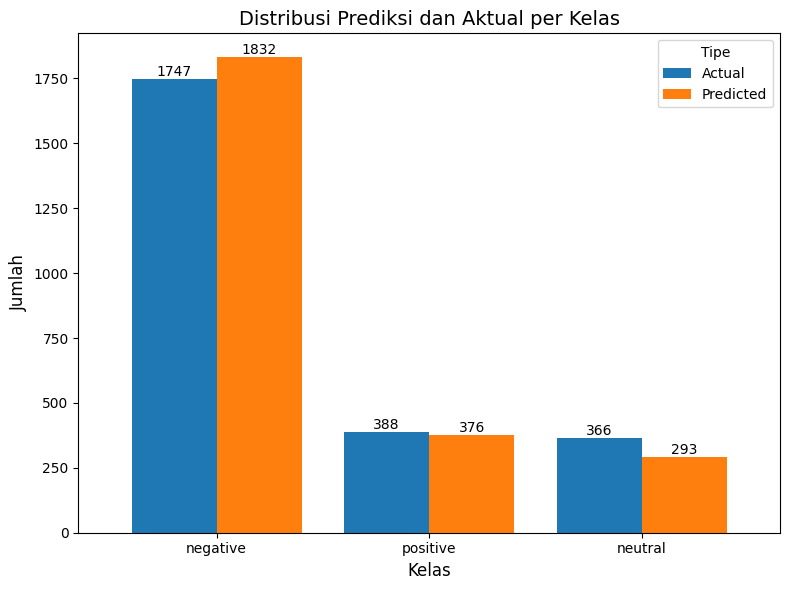

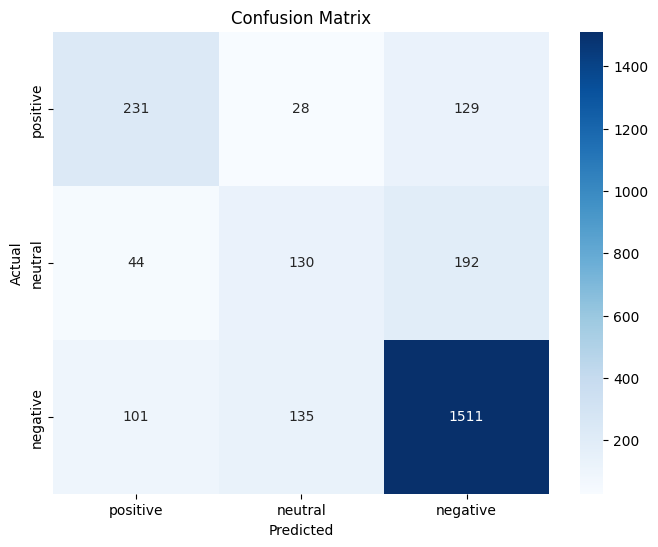


Classification Report:
              precision    recall  f1-score   support

    positive       0.82      0.86      0.84      1747
     neutral       0.44      0.36      0.39       366
    negative       0.61      0.60      0.60       388

    accuracy                           0.75      2501
   macro avg       0.63      0.61      0.61      2501
weighted avg       0.74      0.75      0.74      2501


Hyperparameter Tuning Results:
   learning_rate  epochs  train_acc   val_acc  test_acc
0       0.000003       5   0.839824  0.768985  0.777689
1       0.000003      10   0.941851  0.752598  0.753299
2       0.000003      15   0.972526  0.741407  0.748501


In [ ]:
# Define hyperparameter settings
learning_rates = [3e-6]
epochs_list = [5, 10, 15]

# Store results for each hyperparameter combination
results = []

for lr in learning_rates:
    for n_epochs in epochs_list:
        print(f"\nTraining with Learning Rate: {lr} and Epochs: {n_epochs}\n")

        # Reinitialize model and optimizer
        model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', config=config)
        model = model.cuda()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        # Reset history
        history = defaultdict(list)

        # Training and Validation
        for epoch in range(n_epochs):
            # Training loop
            model.train()
            torch.set_grad_enabled(True)

            total_train_loss = 0
            list_hyp, list_label = [], []

            train_pbar = tqdm(train_loader, leave=True, total=len(train_loader))
            for i, batch_data in enumerate(train_pbar):
                # Forward pass
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Backward pass
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                # Track metrics
                total_train_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                train_pbar.set_description(
                    f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} LR:{get_lr(optimizer):.8f}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['train_acc'].append(metrics['ACC'])

            # Validation loop
            model.eval()
            torch.set_grad_enabled(False)

            total_val_loss = 0
            list_hyp, list_label = [], []

            valid_pbar = tqdm(valid_loader, leave=True, total=len(valid_loader))
            for i, batch_data in enumerate(valid_pbar):
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Track metrics
                total_val_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                valid_pbar.set_description(
                    f"VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(document_sentiment_metrics_fn(list_hyp, list_label))}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['val_acc'].append(metrics['ACC'])

        # Testing loop
        print(f"\nTesting with Learning Rate: {lr} and Epochs: {n_epochs}")
        model.eval()
        torch.set_grad_enabled(False)

        list_hyp, list_label = [], []

        test_pbar = tqdm(test_loader, leave=True, total=len(test_loader))
        for i, batch_data in enumerate(test_pbar):
            _, batch_hyp, batch_label = forward_sequence_classification(
                model, batch_data[:-1], i2w=i2w, device='cuda'
            )
            list_hyp += batch_hyp
            list_label += batch_label

        df = pd.DataFrame({'label':list_hyp}).reset_index()
        print(df)

        # Calculate final metrics for testing
        test_metrics = document_sentiment_metrics_fn(list_hyp, list_label)
        print(f"TEST RESULTS: {metrics_to_string(test_metrics)}")

        # Save final results for this hyperparameter combination
        results.append({
            'learning_rate': lr,
            'epochs': n_epochs,
            'train_acc': history['train_acc'][-1],
            'val_acc': history['val_acc'][-1],
            'test_acc': test_metrics['ACC']
        })

        # Plot training and validation accuracy
        plt.figure(figsize=(8, 5))
        plt.plot(history['train_acc'], label='Train Accuracy')
        plt.plot(history['val_acc'], label='Validation Accuracy')
        plt.title(f'Accuracy for LR={lr}, Epochs={n_epochs}')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.ylim([0, 1])
        plt.show()

        # Load test dataset and calculate confusion matrix
        test_df = pd.read_csv(test_dataset_path, sep='\t', names=['text', 'sentiment'])  # Adjust separator as needed
        test_df['sentiment_predict'] = list_hyp

        # Menghitung distribusi untuk data aktual dan prediksi
        actual_counts = test_df['sentiment'].value_counts()
        predicted_counts = test_df['sentiment_predict'].value_counts()

        # Membuat DataFrame untuk mempermudah visualisasi
        summary_df = pd.DataFrame({
            'Actual': actual_counts,
            'Predicted': predicted_counts
        }).fillna(0)  # Jika ada kelas yang tidak muncul di prediksi atau aktual

        # Membuat diagram batang
        ax = summary_df.plot(kind='bar', figsize=(8, 6), width=0.8)

        # Menambahkan angka di atas setiap batang
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=10)

        # Menambahkan label dan judul
        title = "Distribusi Prediksi dan Aktual per Kelas"
        plt.title(title, fontsize=14)
        plt.xlabel("Kelas", fontsize=12)
        plt.ylabel("Jumlah", fontsize=12)
        plt.xticks(rotation=0)

        # Menampilkan legenda
        plt.legend(title="Tipe", fontsize=10)

        # Menampilkan plot
        plt.tight_layout()
        plt.show()

        #Evaluation
        test_real = test_df['sentiment']
        test_pred = test_df['sentiment_predict']

        # Generate Confusion Matrix
        cm = confusion_matrix(test_real, test_pred, labels=list(w2i.keys()))
        df_cm = pd.DataFrame(cm, index=w2i.keys(), columns=w2i.keys())

        # Visualize Confusion Matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues", xticklabels=w2i.keys(), yticklabels=w2i.keys())
        plt.title("Confusion Matrix")
        plt.ylabel("Actual")
        plt.xlabel("Predicted")
        plt.show()

        # Classification Report
        print("\nClassification Report:")
        print(classification_report(test_real, test_pred, target_names=w2i.keys()))

# Display summary of all results
results_df = pd.DataFrame(results)
print("\nHyperparameter Tuning Results:")
print(results_df)


#2e-7


Training with Learning Rate: 2e-07 and Epochs: 5



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.8824 LR:0.00000020: 100%|██████████| 235/235 [00:51<00:00,  4.53it/s]
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: P

(Epoch 1) TRAIN LOSS:0.8824 ACC:0.64 F1:0.31 REC:0.34 PRE:0.29


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.3876 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:  38%|███▊      | 30/79 [00:04<00:03, 12.57it/s]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3890 ACC:1.00 F1:0.50 REC:0.50 PRE:0.50:  38%|███▊      | 30/79 [00:04<00:03, 12.57

(Epoch 1) VALID LOSS:0.8037 ACC:0.70 F1:0.27 REC:0.33 PRE:0.23


...

(Epoch 5) TRAIN LOSS:0.7017 ACC:0.73 F1:0.43 REC:0.42 PRE:0.69


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.2930 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:   1%|▏         | 1/79 [00:01<01:47,  1.37s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.3099 ACC:0.98 F1:0.49 REC:0.49 PRE:0.50:   4%|▍         | 3/79 [00:01<00:32,  2.37it

(Epoch 5) VALID LOSS:0.6841 ACC:0.75 F1:0.50 REC:0.47 PRE:0.71

Testing with Learning Rate: 2e-07 and Epochs: 5


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:07<00:00, 10.25it/s]


      index     label
0         0  negative
1         1  negative
2         2  negative
3         3  negative
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498   neutral
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.75 F1:0.51 REC:0.47 PRE:0.71


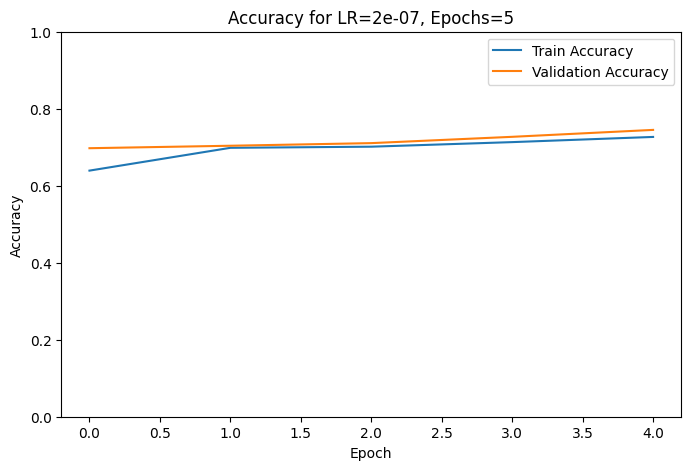

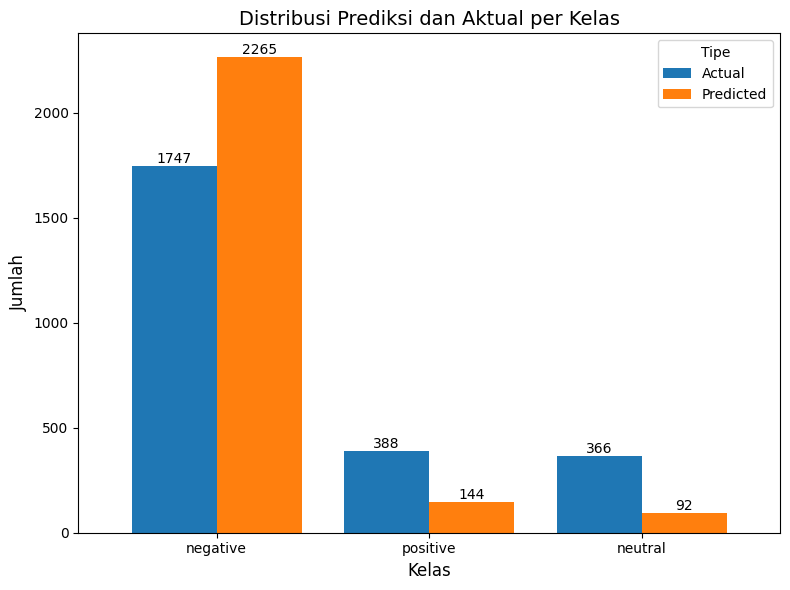

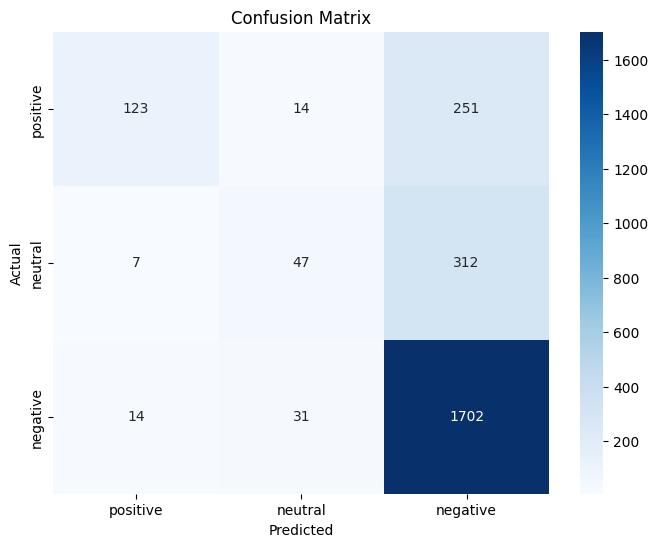


Classification Report:
              precision    recall  f1-score   support

    positive       0.75      0.97      0.85      1747
     neutral       0.51      0.13      0.21       366
    negative       0.85      0.32      0.46       388

    accuracy                           0.75      2501
   macro avg       0.71      0.47      0.51      2501
weighted avg       0.73      0.75      0.69      2501


Training with Learning Rate: 2e-07 and Epochs: 10



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.9111 LR:0.00000020: 100%|██████████| 235/235 [00:51<00:00,  4.55it/s]


(Epoch 1) TRAIN LOSS:0.9111 ACC:0.66 F1:0.29 REC:0.33 PRE:0.30


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.4863 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:  67%|██████▋   | 53/79 [00:05<00:01, 13.10it/s]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.4953 ACC:0.99 F1:0.50 REC:0.50 PRE:0.50:  70%|██████▉   | 55/79 [00:05<00:0

(Epoch 1) VALID LOSS:0.8344 ACC:0.70 F1:0.27 REC:0.33 PRE:0.23


...

(Epoch 10) TRAIN LOSS:0.6352 ACC:0.76 F1:0.55 REC:0.52 PRE:0.68


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.2397 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:   3%|▎         | 2/79 [00:01<00:50,  1.51it/s]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2599 ACC:0.97 F1:0.33 REC:0.32 PRE:0.33:   3%|▎         | 2/79 [00:01<00:50,  1.51it

(Epoch 10) VALID LOSS:0.6335 ACC:0.77 F1:0.59 REC:0.55 PRE:0.70

Testing with Learning Rate: 2e-07 and Epochs: 10


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 11.61it/s]


      index     label
0         0  negative
1         1   neutral
2         2  negative
3         3   neutral
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498   neutral
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.76 F1:0.57 REC:0.54 PRE:0.66


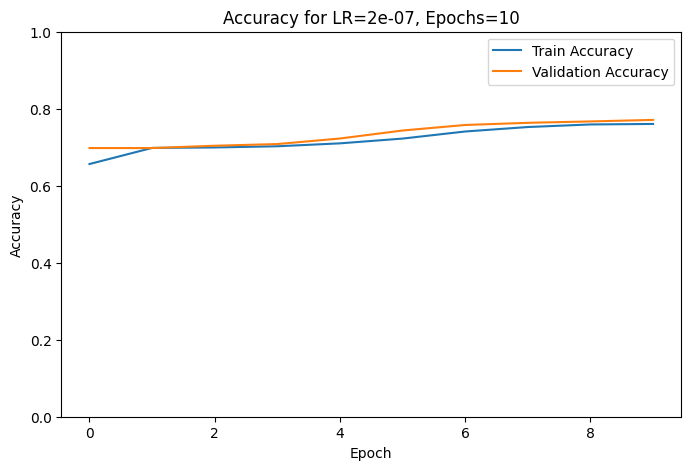

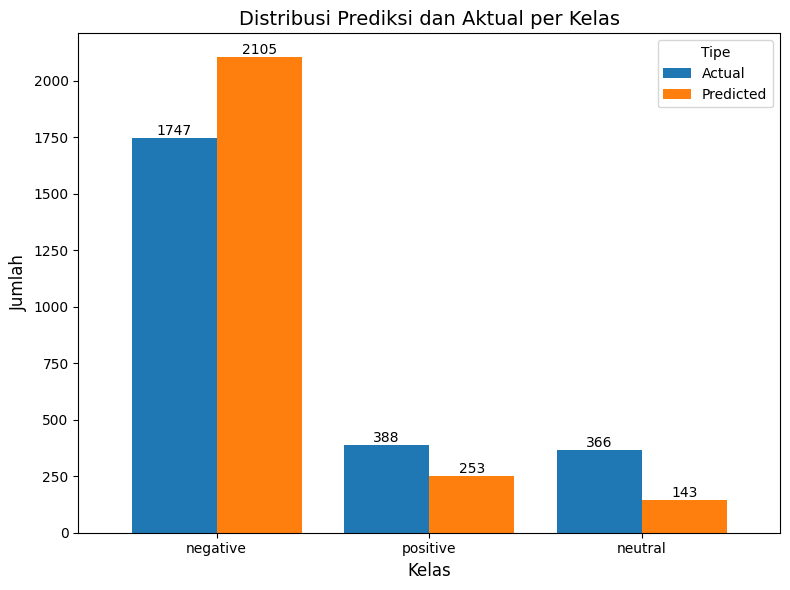

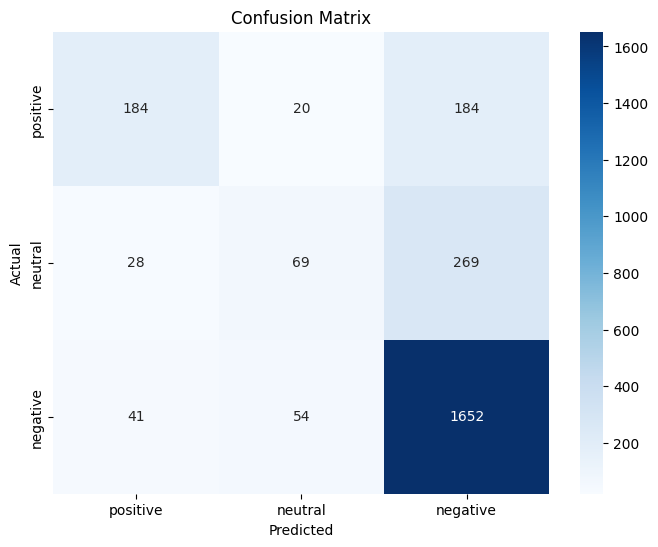


Classification Report:
              precision    recall  f1-score   support

    positive       0.78      0.95      0.86      1747
     neutral       0.48      0.19      0.27       366
    negative       0.73      0.47      0.57       388

    accuracy                           0.76      2501
   macro avg       0.66      0.54      0.57      2501
weighted avg       0.73      0.76      0.73      2501


Training with Learning Rate: 2e-07 and Epochs: 15



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|          | 0/235 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
(Epoch 1) TRAIN LOSS:0.9071 LR:0.00000020: 100%|██████████| 235/235 [00:51<00:00,  4.54it/s]


(Epoch 1) TRAIN LOSS:0.9071 ACC:0.66 F1:0.31 REC:0.34 PRE:0.37


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
VALID LOSS:0.4760 ACC:1.00 F1:1.00 REC:1.00 PRE:1.00:  67%|██████▋   | 53/79 [00:05<00:01, 13.12it/s]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.4853 ACC:0.99 F1:0.50 REC:0.50 PRE:0.50:  70%|██████▉   | 55/79 [00:05<00:0

(Epoch 1) VALID LOSS:0.8173 ACC:0.70 F1:0.27 REC:0.33 PRE:0.23


...

(Epoch 15) TRAIN LOSS:0.5978 ACC:0.77 F1:0.58 REC:0.55 PRE:0.68


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
VALID LOSS:0.2960 ACC:0.97 F1:0.49 REC:0.48 PRE:0.50:   1%|▏         | 1/79 [00:01<01:54,  1.47s/it]/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricW

(Epoch 15) VALID LOSS:0.6140 ACC:0.77 F1:0.61 REC:0.58 PRE:0.69

Testing with Learning Rate: 2e-07 and Epochs: 15


  0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 79/79 [00:06<00:00, 11.46it/s]


      index     label
0         0  negative
1         1   neutral
2         2  negative
3         3  negative
4         4  negative
...     ...       ...
2496   2496  negative
2497   2497  negative
2498   2498   neutral
2499   2499  negative
2500   2500  negative

[2501 rows x 2 columns]
TEST RESULTS: ACC:0.77 F1:0.59 REC:0.57 PRE:0.67


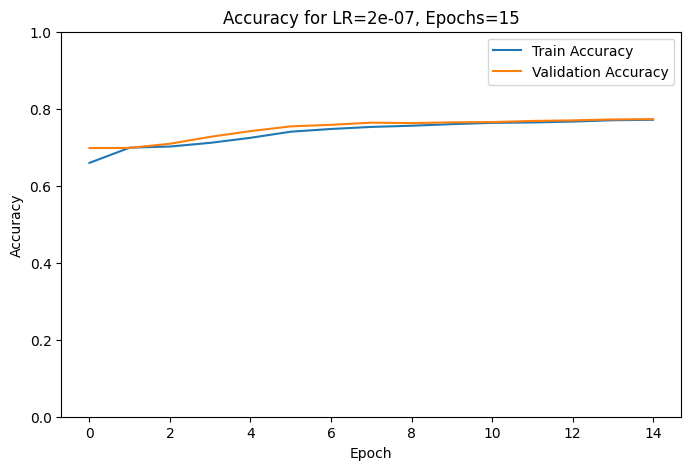

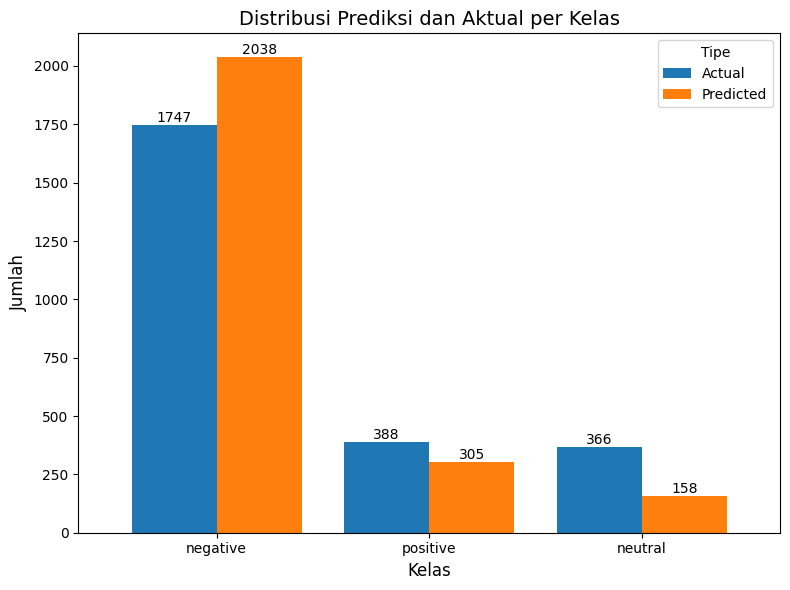

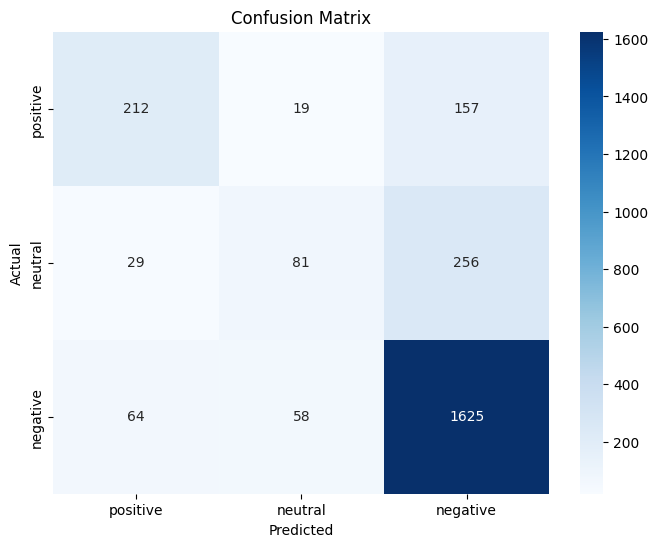


Classification Report:
              precision    recall  f1-score   support

    positive       0.80      0.93      0.86      1747
     neutral       0.51      0.22      0.31       366
    negative       0.70      0.55      0.61       388

    accuracy                           0.77      2501
   macro avg       0.67      0.57      0.59      2501
weighted avg       0.74      0.77      0.74      2501


Hyperparameter Tuning Results:
   learning_rate  epochs  train_acc   val_acc  test_acc
0   2.000000e-07       5   0.726727  0.745004  0.748501
1   2.000000e-07      10   0.760469  0.770983  0.761695
2   2.000000e-07      15   0.771272  0.772982  0.766893


In [ ]:
# Define hyperparameter settings
learning_rates = [2e-7]
epochs_list = [5, 10, 15]

# Store results for each hyperparameter combination
results = []

for lr in learning_rates:
    for n_epochs in epochs_list:
        print(f"\nTraining with Learning Rate: {lr} and Epochs: {n_epochs}\n")

        # Reinitialize model and optimizer
        model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', config=config)
        model = model.cuda()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        # Reset history
        history = defaultdict(list)

        # Training and Validation
        for epoch in range(n_epochs):
            # Training loop
            model.train()
            torch.set_grad_enabled(True)

            total_train_loss = 0
            list_hyp, list_label = [], []

            train_pbar = tqdm(train_loader, leave=True, total=len(train_loader))
            for i, batch_data in enumerate(train_pbar):
                # Forward pass
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Backward pass
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                # Track metrics
                total_train_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                train_pbar.set_description(
                    f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} LR:{get_lr(optimizer):.8f}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) TRAIN LOSS:{total_train_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['train_acc'].append(metrics['ACC'])

            # Validation loop
            model.eval()
            torch.set_grad_enabled(False)

            total_val_loss = 0
            list_hyp, list_label = [], []

            valid_pbar = tqdm(valid_loader, leave=True, total=len(valid_loader))
            for i, batch_data in enumerate(valid_pbar):
                loss, batch_hyp, batch_label = forward_sequence_classification(
                    model, batch_data[:-1], i2w=i2w, device='cuda'
                )

                # Track metrics
                total_val_loss += loss.item()
                list_hyp += batch_hyp
                list_label += batch_label

                valid_pbar.set_description(
                    f"VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(document_sentiment_metrics_fn(list_hyp, list_label))}"
                )

            metrics = document_sentiment_metrics_fn(list_hyp, list_label)
            print(f"(Epoch {epoch+1}) VALID LOSS:{total_val_loss/(i+1):.4f} {metrics_to_string(metrics)}")
            history['val_acc'].append(metrics['ACC'])

        # Testing loop
        print(f"\nTesting with Learning Rate: {lr} and Epochs: {n_epochs}")
        model.eval()
        torch.set_grad_enabled(False)

        list_hyp, list_label = [], []

        test_pbar = tqdm(test_loader, leave=True, total=len(test_loader))
        for i, batch_data in enumerate(test_pbar):
            _, batch_hyp, batch_label = forward_sequence_classification(
                model, batch_data[:-1], i2w=i2w, device='cuda'
            )
            list_hyp += batch_hyp
            list_label += batch_label

        df = pd.DataFrame({'label':list_hyp}).reset_index()
        print(df)

        # Calculate final metrics for testing
        test_metrics = document_sentiment_metrics_fn(list_hyp, list_label)
        print(f"TEST RESULTS: {metrics_to_string(test_metrics)}")

        # Save final results for this hyperparameter combination
        results.append({
            'learning_rate': lr,
            'epochs': n_epochs,
            'train_acc': history['train_acc'][-1],
            'val_acc': history['val_acc'][-1],
            'test_acc': test_metrics['ACC']
        })

        # Plot training and validation accuracy
        plt.figure(figsize=(8, 5))
        plt.plot(history['train_acc'], label='Train Accuracy')
        plt.plot(history['val_acc'], label='Validation Accuracy')
        plt.title(f'Accuracy for LR={lr}, Epochs={n_epochs}')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.ylim([0, 1])
        plt.show()

        # Load test dataset and calculate confusion matrix
        test_df = pd.read_csv(test_dataset_path, sep='\t', names=['text', 'sentiment'])  # Adjust separator as needed
        test_df['sentiment_predict'] = list_hyp

        # Menghitung distribusi untuk data aktual dan prediksi
        actual_counts = test_df['sentiment'].value_counts()
        predicted_counts = test_df['sentiment_predict'].value_counts()

        # Membuat DataFrame untuk mempermudah visualisasi
        summary_df = pd.DataFrame({
            'Actual': actual_counts,
            'Predicted': predicted_counts
        }).fillna(0)  # Jika ada kelas yang tidak muncul di prediksi atau aktual

        # Membuat diagram batang
        ax = summary_df.plot(kind='bar', figsize=(8, 6), width=0.8)

        # Menambahkan angka di atas setiap batang
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=10)

        # Menambahkan label dan judul
        title = "Distribusi Prediksi dan Aktual per Kelas"
        plt.title(title, fontsize=14)
        plt.xlabel("Kelas", fontsize=12)
        plt.ylabel("Jumlah", fontsize=12)
        plt.xticks(rotation=0)

        # Menampilkan legenda
        plt.legend(title="Tipe", fontsize=10)

        # Menampilkan plot
        plt.tight_layout()
        plt.show()

        #Evaluation
        test_real = test_df['sentiment']
        test_pred = test_df['sentiment_predict']

        # Generate Confusion Matrix
        cm = confusion_matrix(test_real, test_pred, labels=list(w2i.keys()))
        df_cm = pd.DataFrame(cm, index=w2i.keys(), columns=w2i.keys())

        # Visualize Confusion Matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues", xticklabels=w2i.keys(), yticklabels=w2i.keys())
        plt.title("Confusion Matrix")
        plt.ylabel("Actual")
        plt.xlabel("Predicted")
        plt.show()

        # Classification Report
        print("\nClassification Report:")
        print(classification_report(test_real, test_pred, target_names=w2i.keys()))

# Display summary of all results
results_df = pd.DataFrame(results)
print("\nHyperparameter Tuning Results:")
print(results_df)
